# 프로젝트: SentencePiece 사용하기 (v2)

멋진 단어사전 만들기 — 5단계 프로젝트. 원본 과제 흐름(Step 0~4) 뒤에 6주차 방식의 개인 실험을 붙였다. 원본에 없는 셀은 제목에 **[개인 실험]** 이라고 표시했다.

## 한눈에 보기

NSMC 전체(학습 131,564 / 검증 14,618 / 테스트 49,157), BiLSTM, 시드 5개 평균 ± 표준편차, 설정 선택은 검증으로만 했다. Colab Pro A100에서 실험 50회에 16분 걸렸다.

| 질문 | 답 (근거) |
|---|---|
| SentencePiece로 바꾸면 성능이 좋아지나? | **아니다. MeCab이 더 좋다.** 검증 최고 MeCab-8000(검증 0.8647 ± 0.0017, 테스트 0.8620 ± 0.0022). SPM 최고는 unigram-16000(검증 0.8515 ± 0.0006, 테스트 0.8469 ± 0.0013)이다. 같은 시드끼리 비교하면 **1.51%p ± 0.22%p** 차이가 났고, 시드 5개 모두 MeCab이 높았다 |
| model_type, vocab_size를 바꾸면? | **거의 차이 없다.** SPM 6개의 검증 평균이 0.8489~0.8515로 0.26%p 안에 있다. 시드 표준편차(0.06~0.23%p)와 비슷한 크기다 |
| v1 회고의 "vocab이 크면 희귀 토큰 때문에 떨어진다"는? | **틀렸다.** 검증 기준으로는 vocab 16000이 SPM 중 가장 높았다. 학습 데이터에 5번 미만 나온 토큰도 SPM vocab의 0.05~0.85%뿐이었다 |
| 그럼 차이는 어디서 오나? | **`<unk>` 때문은 아니다.** MeCab-4000은 검증 토큰의 7.8%가 `<unk>`인데도(SPM은 약 0.1%) SPM보다 1%p 넘게 높았다. 어간과 어미를 나누는 방식의 차이로 보인다(오답 분석) |
| 몇 에폭이 맞나? | **4~5에폭.** 검증 정확도는 4에폭 전후에 가장 높았다. 그 뒤로는 학습 loss가 계속 줄어도 검증 정확도는 떨어졌다(과적합) |
| 60토큰에서 잘린 게 손해였나? | **거의 아니다.** MAX_LEN을 128로 늘려도 검증 +0.04~0.14%p로, 시드 표준편차 수준이었다 |
| Okt는? | 검증 0.8532 ± 0.0012로 MeCab과 SPM 사이다. 형태소 분석이 742초 걸렸다(MeCab 13초의 약 57배) |
| [추가 실험] Kkma는? | **정확도는 MeCab과 거의 같다**(검증 0.8639 ± 0.0019, MeCab-8000보다 0.08%p 낮음). 대신 11프로세스 병렬로도 형태소 분석에 35.8분이 걸렸다(MeCab 13초). Okt·SentencePiece보다 1%p 넘게 높았다 |
| [선택 과제] fastText 사전학습 벡터를 쓰면? | **SentencePiece만 크게 오른다.** 미세조정하면 SPM-unigram-16000이 같은 시드끼리 +1.36%p ± 0.27%p(테스트 0.8616)로 MeCab 수준까지 따라오고, MeCab은 거의 그대로다(-0.07%p). 벡터를 고정하면 둘 다 약 -0.5%p 떨어진다 |

v1(테스트 0.8436)보다 전체적으로 약 2%p 오른 이유는 두 가지로 보인다. 학습 데이터가 약 2.2배로 늘었고, 검증으로 최고 에폭을 골랐다.

## 평가 기준 확인

| 평가 기준 | 노트북에서 확인할 곳 |
|---|---|
| 코퍼스 분석, 전처리, SentencePiece 적용, 토크나이저 구현 및 동작 | **코퍼스 분석: 뉴스 말뭉치**(정제 단계별 개수·길이 분포) → **Step 2** SentencePiece 학습·인코딩/디코딩 → **Step 3** `sp_tokenize()` 구현·출력 → **Step 4-0** NSMC 정제·라벨·길이·어절 분석 → **[개인 실험] 1~2** NSMC용 SentencePiece 6개 학습, 토큰화 예시, 토큰 통계 |
| SentencePiece 분류기가 수렴하고 test accuracy 80% 이상 | **[개인 실험] 4·5** SentencePiece 6개 설정 모두 테스트 **0.846~0.850**(시드 5개 평균). **[개인 실험] 6** 러닝 커브에서 학습 loss가 꾸준히 줄고, 검증 정확도는 3~5에폭에서 최고 |
| 다른 토크나이저·옵션과 체계적 비교 | **[개인 실험] 5** MeCab·Okt 포함 10개 비교(시드 5개 평균 ± 표준편차) / **7** 같은 vocab 크기 비교 / **8** MAX_LEN before/after / **9** 오답 분석·길이별 정확도 / **[추가 실험]** Kkma / **[선택 과제]** fastText 사전학습 벡터(무작위·미세조정·고정 비교) |

**Colab 사용법:** 런타임 유형을 GPU(A100 권장)로 바꾸고 **모두 실행**. 설치 셀은 처음 한 번만 필요하다.

## Colab 설치 (konlpy, sentencepiece, MeCab, Okt용 Java)

In [1]:
!pip install -q konlpy sentencepiece
%cd /content
!test -d Mecab-ko-for-Google-Colab || git clone -q https://github.com/SOMJANG/Mecab-ko-for-Google-Colab.git
%cd /content/Mecab-ko-for-Google-Colab
!bash install_mecab-ko_on_colab_light_220429.sh > /tmp/mecab_install.log 2>&1; tail -n 3 /tmp/mecab_install.log
%cd /content
!java -version 2>/dev/null || (apt-get -qq update > /dev/null && apt-get -qq install -y default-jdk-headless > /dev/null && echo "java installed")

/content
/content/Mecab-ko-for-Google-Colab
블로그에 해결 방법을 남겨주신 tana님 감사합니다.
light 버전 작성 : Dogdriip님 ( https://github.com/Dogdriip )
문제를 해결해주신 combacsa님 감사합니다.
/content
[0.021s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.021s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


## Step 0. 라이브러리 버전 확인 (원본)

In [2]:
import torch
from torch.nn.utils.rnn import pad_sequence
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import konlpy
print(torch.__version__)
print(np.__version__)
print(matplotlib.__version__)
print(konlpy.__version__)

2.11.0+cu130
2.4.6
3.10.0
0.6.0


## 데이터 준비 (2단계와 같은 정제: 중복 제거, 길이 10 이상 150 미만)

In [3]:
import os
if not os.path.exists('korean-english-park.train.ko'):
    !wget -q https://github.com/jungyeul/korean-parallel-corpora/raw/master/korean-english-news-v1/korean-english-park.train.tar.gz
    !tar -xzf korean-english-park.train.tar.gz

with open('korean-english-park.train.ko', 'r', encoding='utf-8') as f:
    raw = f.read().splitlines()
print('원본:', len(raw))

cleaned_corpus = list(set(raw))
filtered_corpus = [s for s in cleaned_corpus if 10 <= len(s) < 150]
print('정제 후:', len(filtered_corpus))

원본: 94123
정제 후: 76908


### 코퍼스 분석: 뉴스 말뭉치

Step 2에서 SentencePiece를 학습할 한국어 뉴스 문장이다. 과제 2단계와 같은 기준(중복 제거, 10자 이상 150자 미만)으로 정제하면서, 무엇이 얼마나 빠지는지와 정제 전후 길이 분포를 확인한다.

> 이 분석 셀은 Colab 실행 뒤에 추가해 로컬 PC에서 같은 데이터로 실행했다(GPU 불필요, 정제 개수는 Colab 결과와 같다).

원본                94,123문장  길이 최소   1 / 최대 377 / 평균  60.8 / 중앙값   59
중복 제거             77,591문장  길이 최소   1 / 최대 377 / 평균  64.5 / 중앙값   62
+ 10자 이상 150자 미만  76,908문장  길이 최소  10 / 최대 149 / 평균  64.0 / 중앙값   62

제거: 중복 16,532문장 / 10자 미만 197문장 / 150자 이상 486문장
3자 이하 문장 예: ['통계청', '4.', '코브:', '음식', '1.', '’', '▲쇼핑', 'Q:']
가장 많이 중복된 문장:
  554회  홍콩 닭장 아파트 생활
  554회  잭슨 소장품 경매 장갑 최고가 낙...
  554회  수잔 보일 데뷔 음반 예약주문 1...


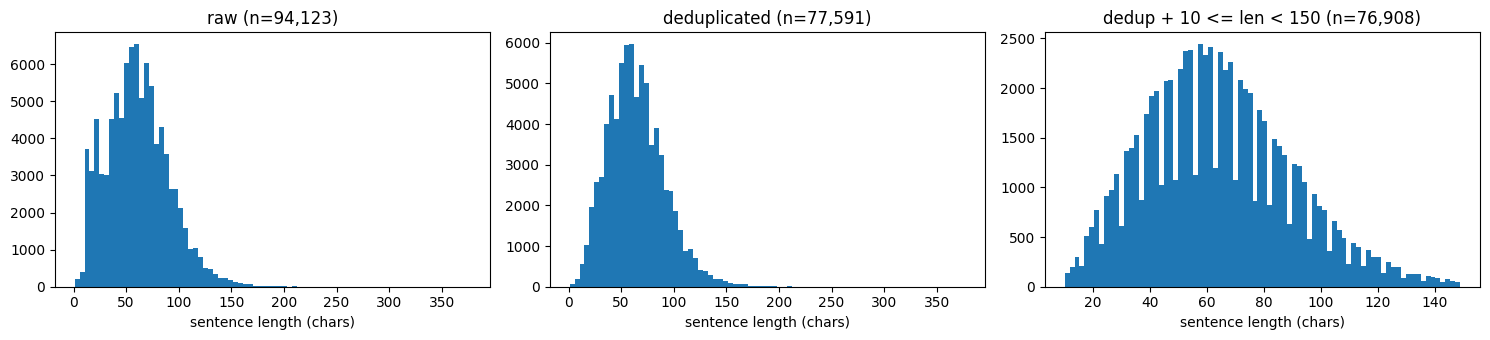

In [ ]:
# 코퍼스 분석: 뉴스 말뭉치 (Step 2 SentencePiece 학습용)
import os
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

if not os.path.exists('korean-english-park.train.ko'):
    !wget -q https://github.com/jungyeul/korean-parallel-corpora/raw/master/korean-english-news-v1/korean-english-park.train.tar.gz
    !tar -xzf korean-english-park.train.tar.gz
with open('korean-english-park.train.ko', 'r', encoding='utf-8') as f:
    raw = f.read().splitlines()

def describe(name, sents):
    l = np.array([len(s) for s in sents])
    print(f'{name:16s} {len(sents):7,d}문장  길이 최소 {l.min():3d} / 최대 {l.max():3d} / 평균 {l.mean():5.1f} / 중앙값 {np.median(l):4.0f}')
    return l

uniq = list(set(raw))
filtered = [s for s in uniq if 10 <= len(s) < 150]
l_raw = describe('원본', raw)
l_uniq = describe('중복 제거', uniq)
l_filt = describe('+ 10자 이상 150자 미만', filtered)
print(f'\n제거: 중복 {len(raw) - len(uniq):,}문장 / 10자 미만 {(l_uniq < 10).sum():,}문장 / 150자 이상 {(l_uniq >= 150).sum():,}문장')
print('3자 이하 문장 예:', [s for s in uniq if len(s) <= 3][:8])
print('가장 많이 중복된 문장:')
for s, c in Counter(raw).most_common(3):
    print(f'  {c}회  {s[:60]}')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, l, title in zip(axes, [l_raw, l_uniq, l_filt], ['raw', 'deduplicated', 'dedup + 10 <= len < 150']):
    ax.hist(l, bins=80)
    ax.set_title(f'{title} (n={len(l):,})')
    ax.set_xlabel('sentence length (chars)')
plt.tight_layout()
plt.show()

- 중복이 16,532문장(원본의 17.6%)이었다. 554번씩 반복된 `홍콩 닭장 아파트 생활` 같은 문장은 기사 제목 조각으로 보인다.
- 10자 미만 197문장은 `통계청`, `4.`, `Q:` 같은 조각이라 뺐다. 150자 이상 486문장은 0.6%라 빼도 손실이 적다.
- 최종 76,908문장, 평균 64자다. 위 Step 2에서 SentencePiece를 학습할 때 이 문장들을 쓴다.

## Step 1. SentencePiece 설치 (원본)

In [4]:
!pip install -q sentencepiece

## Step 2. SentencePiece 모델 학습 (원본)

In [5]:
import sentencepiece as spm
temp_file = 'korean-english-park.train.ko.temp'
vocab_size = 8000

with open(temp_file, 'w', encoding='utf-8') as f:
    for row in filtered_corpus:
        f.write(str(row) + '\n')

spm.SentencePieceTrainer.Train(
    '--input={} --model_prefix=korean_spm --vocab_size={}'.format(temp_file, vocab_size)
)
!ls -l korean_spm*

-rw-r--r-- 1 root root 380936 Nov  5 04:47 korean_spm.model
-rw-r--r-- 1 root root 147830 Nov  5 04:47 korean_spm.vocab


In [6]:
s = spm.SentencePieceProcessor()
s.Load('korean_spm.model')

tokensIDs = s.EncodeAsIds('아버지가방에들어가신다.')
print(tokensIDs)
print(s.SampleEncodeAsPieces('아버지가방에들어가신다.', -1, 0.1))
print(s.DecodeIds(tokensIDs))

[1202, 10, 318, 6, 3748, 10, 287, 31, 4]
['▁아', '버', '지', '가', '방', '에', '들어', '가', '신', '다', '.']
아버지가방에들어가신다.


## Step 3. sp_tokenize() 함수

원본 코드에서 바꾼 곳은 표시한 줄뿐이다. `EncodeAsIds`는 list를 돌려주는데 `pad_sequence`는 tensor만 받아서, 원본 그대로면 `TypeError`가 난다. `max_len`(문장 자르기)과 `encoding='utf-8'`은 실험용으로 더했다.

In [7]:
def sp_tokenize(s, corpus, vocab_path='./korean_spm.vocab', max_len=None):
    tensor = []
    for sen in corpus:
        ids = s.EncodeAsIds(sen)
        if max_len:
            ids = ids[:max_len]
        # 📄 원본: tensor.append(s.EncodeAsIds(sen))
        # 🔧 수정: list → tensor (pad_sequence는 tensor만 받는다)
        tensor.append(torch.tensor(ids, dtype=torch.long))

    with open(vocab_path, 'r', encoding='utf-8') as f:
        vocab = f.readlines()

    word_index = {}
    index_word = {}
    for idx, line in enumerate(vocab):
        word = line.split('\t')[0]
        word_index.update({word: idx})
        index_word.update({idx: word})

    tensor = pad_sequence(tensor, batch_first=True, padding_value=0)
    return tensor, word_index, index_word

tensor, word_index, index_word = sp_tokenize(s, filtered_corpus[:5])
print(tensor.shape)
print(tensor[0])

torch.Size([5, 34])
tensor([ 198,  551,  601, 5456,  261,  590,  565,    5,  403,  284,   12,  349,
          58,   18,  829,   72, 2046,   32, 2498, 7970,  374,   36,    4,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0])


## Step 4. 네이버 영화리뷰(NSMC) 감정 분석에 SentencePiece 적용

과제 요구: ① NSMC로 SentencePiece 학습 ② `sp_tokenize()`로 토큰화 ③ 감정 분석 모델 재학습 ④ KoNLPy 형태소 분석기와 비교 ⑤ `model_type`, `vocab_size`를 바꿔 가며 확인.

### v1 결과 (참고)

처음에는 학습 6만 / 테스트 2만 샘플, 시드 1개, 4에폭으로 돌리고 **테스트셋으로 바로 비교**했다.

| 토크나이저 | test acc |
|---|---|
| MeCab (vocab 16000) | 0.8436 |
| SPM unigram 4000 | 0.8344 |
| SPM unigram 8000 | 0.8332 |
| SPM bpe 4000 | 0.8331 |
| SPM bpe 8000 | 0.8311 |
| SPM bpe 16000 | 0.8255 |
| SPM unigram 16000 | 0.8247 |

이 결과로는 세 가지를 알 수 없었다.
- 1%p 차이가 시드 하나 때문에 생긴 우연인지
- 테스트로 설정을 골라서 숫자가 부풀려지지 않았는지
- 4에폭이 적당했는지

회고에 쓴 "vocab이 크면 희귀 토큰 때문에 떨어진다"도 확인하지 않은 추측이었다. 아래 개인 실험에서 같은 질문을 다시 확인한다.

## Step 4-0. NSMC 코퍼스 분석과 전처리

감정 분석에 쓸 네이버 영화리뷰 데이터다. 아래 [개인 실험] 0의 `load()`와 같은 순서(결측 → 중복 → 빈 문장 제거)로 정제하면서 단계마다 몇 개가 빠지는지 세고, 라벨 비율과 리뷰 길이를 확인한다.

> 이 분석 셀은 Colab 실행 뒤에 추가해 로컬 PC에서 같은 데이터로 실행했다(GPU 불필요, 정제 개수는 Colab 결과와 같다).

,원본,결측 제거,중복 제거,빈 문장 제거,최종,긍정 비율,길이 최소,길이 최대,길이 평균,길이 중앙값,길이 p95
파일,,,,,,,,,,,
ratings_train.txt,150000,5,3813,0,146182,0.498,1,146,36.0,27.0,108.0
ratings_test.txt,50000,3,840,0,49157,0.503,1,144,35.8,27.0,109.0


학습·테스트에 똑같이 들어 있는 리뷰: 796개
긍정 리뷰 평균 길이 35.4자, 평균 어절 7.7개


부정 리뷰 평균 길이 36.5자, 평균 어절 7.8개


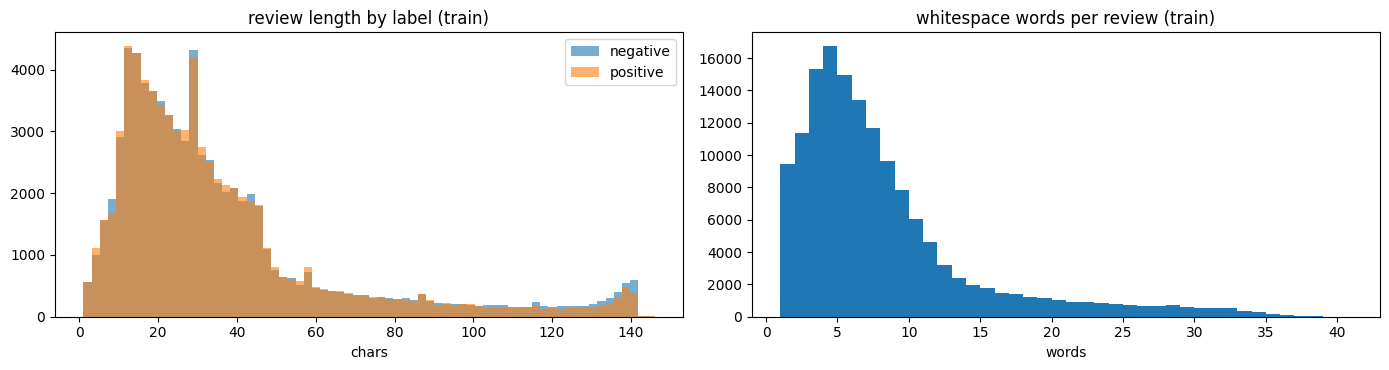

2자 이하 리뷰 예: ['최고', '졸작', '대박', '아', '버려', '망함', '굳굳', '안습', '잼', '망작']
긍정 리뷰에 많이 나온 어절: ['영화', '정말', '너무', '진짜', '이', '수', '최고의', '영화.', '잘', '더', '보고', '본', '영화를', '그', '이런']


부정 리뷰에 많이 나온 어절: ['영화', '너무', '진짜', '정말', '그냥', '이', '왜', '이런', '영화.', '다', '좀', '이건', '더', '영화는', '영화를']


In [ ]:
# 코퍼스 분석: NSMC 영화리뷰 (감정 분석용)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

for fname in ['ratings_train.txt', 'ratings_test.txt']:
    if not os.path.exists(fname):
        !wget -q https://raw.githubusercontent.com/e9t/nsmc/master/{fname}

rows, cleaned = [], {}
for fname in ['ratings_train.txt', 'ratings_test.txt']:
    df = pd.read_table(fname)
    n_raw = len(df)
    n_na = df['document'].isna().sum()
    df = df.dropna()
    n_dup = df.duplicated(subset=['document']).sum()
    df = df.drop_duplicates(subset=['document'])
    n_empty = (df['document'].str.strip() == '').sum()
    df = df[df['document'].str.strip() != '']
    cleaned[fname] = df
    length = df['document'].str.len()
    rows.append({'파일': fname, '원본': n_raw, '결측 제거': n_na, '중복 제거': n_dup, '빈 문장 제거': n_empty,
                 '최종': len(df), '긍정 비율': round(df['label'].mean(), 3),
                 '길이 최소': length.min(), '길이 최대': length.max(), '길이 평균': round(length.mean(), 1),
                 '길이 중앙값': length.median(), '길이 p95': length.quantile(0.95)})
display(pd.DataFrame(rows).set_index('파일'))

train, test = cleaned['ratings_train.txt'], cleaned['ratings_test.txt']
print(f"학습·테스트에 똑같이 들어 있는 리뷰: {len(set(train['document']) & set(test['document'])):,}개")
for label, name in [(1, '긍정'), (0, '부정')]:
    part = train.loc[train['label'] == label, 'document']
    print(f'{name} 리뷰 평균 길이 {part.str.len().mean():.1f}자, 평균 어절 {part.str.split().str.len().mean():.1f}개')

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for label, name in [(0, 'negative'), (1, 'positive')]:
    axes[0].hist(train.loc[train['label'] == label, 'document'].str.len(), bins=70, alpha=0.6, label=name)
axes[0].set_title('review length by label (train)')
axes[0].set_xlabel('chars')
axes[0].legend()
axes[1].hist(train['document'].str.split().str.len(), bins=40)
axes[1].set_title('whitespace words per review (train)')
axes[1].set_xlabel('words')
plt.tight_layout()
plt.show()

print('2자 이하 리뷰 예:', train.loc[train['document'].str.len() <= 2, 'document'].head(10).tolist())
for label, name in [(1, '긍정'), (0, '부정')]:
    cnt = Counter(w for doc in train.loc[train['label'] == label, 'document'] for w in doc.split())
    print(f'{name} 리뷰에 많이 나온 어절:', [w for w, _ in cnt.most_common(15)])

- **정제**: 결측 8개, 중복 4,653개(학습 3,813 + 테스트 840)를 지웠고 빈 문장은 없었다. 학습 146,182 / 테스트 49,157개가 남았다.
- **라벨**: 긍정 비율이 0.498 / 0.503으로 거의 반반이라, 정확도를 평가 지표로 그대로 써도 된다.
- **길이**: 리뷰는 평균 36자, 중앙값 27자로 짧다. 긍정(35.4자)과 부정(36.5자)의 길이 차이도 거의 없어서, 길이만으로는 감정을 가를 수 없다. 140자 근처에 작은 봉우리가 있는데, 리뷰 글자 수 제한(140자) 때문으로 보인다.
- **짧은 리뷰**: `최고`, `졸작`, `망작`처럼 2자 이하 리뷰도 감정이 분명해서 지우지 않았다.
- **어절**: 긍정에는 `최고의`, 부정에는 `그냥`, `왜`가 많지만 `영화`, `너무`, `진짜`는 양쪽에 다 많다. 또 `영화.`, `영화를`, `영화는`이 따로 세어진다. 공백 기준으로는 같은 단어가 흩어진다는 뜻이라, 형태소나 서브워드 단위로 나눌 필요가 있다.
- **확인한 점**: 학습과 테스트에 똑같은 리뷰가 796개(테스트의 1.6%) 있다. 과제 데이터를 그대로 쓰려고 빼지 않았다(빼고 다시 평가하지는 않았다).

## [개인 실험] 0. 설정과 데이터 분할

- NSMC 전체를 쓴다(v1은 샘플링). 학습 데이터에서 **검증 10%를 라벨 비율을 유지해 떼어 낸다**.
- 에폭과 설정 선택은 **검증 정확도**로만 하고, 테스트는 모델마다 **최고 검증 에폭의 모델로 한 번만** 잰다.
- 설정마다 **시드 5개**(모델 초기값과 배치 순서가 바뀜)로 돌려 평균 ± 표준편차를 본다.

In [8]:
import random, copy, time, json
import pandas as pd
from collections import Counter
import torch.nn as nn

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device, torch.cuda.get_device_name(0) if device == 'cuda' else '')

SEEDS = [0, 1, 2, 3, 4]
EPOCHS = 10
MAX_LEN = 60
BATCH = 256

!wget -q -nc https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
!wget -q -nc https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt

def load(path):
    df = pd.read_table(path).dropna().drop_duplicates(subset=['document'])
    df['document'] = df['document'].str.replace('\n', ' ')
    return df[df['document'].str.strip() != ''].reset_index(drop=True)

train_all = load('ratings_train.txt')
test_df = load('ratings_test.txt')
val_df = train_all.groupby('label', group_keys=False).sample(frac=0.1, random_state=42)
train_df = train_all.drop(val_df.index)

texts = {'train': train_df['document'].tolist(), 'val': val_df['document'].tolist(), 'test': test_df['document'].tolist()}
labels = {'train': train_df['label'].values, 'val': val_df['label'].values, 'test': test_df['label'].values}
for k in texts:
    print(f'{k:5s} {len(texts[k]):7,d}개  긍정 비율 {labels[k].mean():.3f}')

cuda NVIDIA A100-SXM4-80GB
train 131,564개  긍정 비율 0.498
val    14,618개  긍정 비율 0.498
test   49,157개  긍정 비율 0.503


## [개인 실험] 1. 토크나이저 준비

- SentencePiece: `unigram` / `bpe` × vocab 4000 / 8000 / 16000. **학습 데이터로만** 학습하고, 토큰화는 위의 `sp_tokenize()`를 쓴다.
- KoNLPy: MeCab(vocab 4000 / 8000 / 16000, SentencePiece와 같은 크기로 비교) + Okt(16000).
- 형태소 vocab은 학습 데이터에서 많이 나온 순서로 자르고, 없는 단어는 `<unk>`(1)로 둔다.
- Kkma는 아주 느려서 여기서는 빼고, 아래 **[추가 실험] Kkma**에서 병렬로 따로 돌려 같은 조건으로 비교했다(11프로세스로 35.8분).

In [9]:
def to_tensor(id_lists, max_len):
    seqs = [torch.tensor(ids[:max_len] or [1], dtype=torch.long) for ids in id_lists]
    return pad_sequence(seqs, batch_first=True, padding_value=0)

TOK = {}

with open('nsmc_train_v2.txt', 'w', encoding='utf-8') as f:
    for t in texts['train']:
        f.write(t + '\n')

def add_spm(model_type, vocab_size):
    name = f'SPM-{model_type}-{vocab_size}'
    prefix = f'nsmc_v2_{model_type}_{vocab_size}'
    spm.SentencePieceTrainer.Train(
        f'--input=nsmc_train_v2.txt --model_prefix={prefix} --vocab_size={vocab_size} '
        f'--model_type={model_type} --pad_id=0 --unk_id=1 --bos_id=2 --eos_id=3 --minloglevel=2'
    )
    sp = spm.SentencePieceProcessor()
    sp.Load(f'{prefix}.model')
    X = {}
    for k, v in texts.items():
        X[k], wi, _ = sp_tokenize(sp, v, f'{prefix}.vocab', MAX_LEN)
    TOK[name] = dict(ids={k: [sp.EncodeAsIds(t) for t in v] for k, v in texts.items()},
                     X=X, vocab_size=len(wi), n_special=4, pieces=sp.EncodeAsPieces)

MORPH = {}
def add_morph(tagger, fn, vocab_size):
    if tagger not in MORPH:
        t0 = time.time()
        MORPH[tagger] = {k: [fn(t) for t in v] for k, v in texts.items()}
        print(f'{tagger} 형태소 분석 {time.time() - t0:.0f}초')
    toks = MORPH[tagger]
    cnt = Counter(w for ts in toks['train'] for w in ts)
    word_index = {w: i + 2 for i, (w, _) in enumerate(cnt.most_common(vocab_size - 2))}  # 0=pad, 1=unk
    ids = {k: [[word_index.get(w, 1) for w in ts] for ts in v] for k, v in toks.items()}
    TOK[f'{tagger}-{vocab_size}'] = dict(ids=ids, X={k: to_tensor(v, MAX_LEN) for k, v in ids.items()},
                                         vocab_size=vocab_size, n_special=2, pieces=fn)

t0 = time.time()
for mt in ['unigram', 'bpe']:
    for vs in [4000, 8000, 16000]:
        add_spm(mt, vs)
print(f'SentencePiece 6개 {time.time() - t0:.0f}초')

from konlpy.tag import Mecab
mecab = Mecab()
for vs in [4000, 8000, 16000]:
    add_morph('MeCab', mecab.morphs, vs)

try:
    from konlpy.tag import Okt
    okt = Okt()
    add_morph('Okt', okt.morphs, 16000)
except Exception as e:
    print('Okt 건너뜀:', repr(e)[:300])

print(list(TOK))

SentencePiece 6개 96초
MeCab 형태소 분석 13초
Okt 형태소 분석 742초
['SPM-unigram-4000', 'SPM-unigram-8000', 'SPM-unigram-16000', 'SPM-bpe-4000', 'SPM-bpe-8000', 'SPM-bpe-16000', 'MeCab-4000', 'MeCab-8000', 'MeCab-16000', 'Okt-16000']


## [개인 실험] 2. 토큰 통계: "vocab이 크면 희귀 토큰 때문에 떨어진다"가 맞나?

- `avg_tokens`: 문장당 평균 토큰 수 / `cut_ratio`: MAX_LEN(60)을 넘어 잘리는 문장 비율
- `unk_val`: 검증 데이터 토큰 중 `<unk>` 비율
- `rare_vocab`: vocab 중 학습 데이터에 5번 미만 나온 토큰 비율 (임베딩이 거의 학습되지 않는 토큰)

In [10]:
rows = []
for name, t in TOK.items():
    tr, va = t['ids']['train'], t['ids']['val']
    lens = np.array([len(x) for x in tr])
    cnt = Counter(i for x in tr for i in x)
    vocab_ids = range(t['n_special'], t['vocab_size'])
    va_total = sum(len(x) for x in va)
    rows.append(dict(tokenizer=name, vocab=t['vocab_size'],
                     avg_tokens=lens.mean(), p95_tokens=np.percentile(lens, 95),
                     cut_ratio=(lens > MAX_LEN).mean(),
                     unk_val=sum(x.count(1) for x in va) / va_total,
                     rare_vocab=np.mean([cnt.get(i, 0) < 5 for i in vocab_ids])))
token_stats = pd.DataFrame(rows).set_index('tokenizer')
token_stats.round(4)

,vocab,avg_tokens,p95_tokens,cut_ratio,unk_val,rare_vocab
tokenizer,,,,,,
SPM-unigram-4000,4000,20.2035,61.0,0.0506,0.0009,0.0008
SPM-unigram-8000,8000,17.3102,52.0,0.0304,0.0010,0.0005
SPM-unigram-16000,16000,15.3856,46.0,0.0149,0.0011,0.0010
SPM-bpe-4000,4000,19.7442,59.0,0.0475,0.0009,0.0005
SPM-bpe-8000,8000,16.9808,51.0,0.0273,0.0010,0.0025
SPM-bpe-16000,16000,15.1171,45.0,0.0124,0.0012,0.0085
MeCab-4000,4000,18.7179,56.0,0.0397,0.0779,0.0000
MeCab-8000,8000,18.7179,56.0,0.0397,0.0463,0.0000
MeCab-16000,16000,18.7179,56.0,0.0397,0.0258,0.0564


In [11]:
pd.set_option('display.max_colwidth', 120)
samples = [texts['val'][i] for i in [0, 1, 2]]
pd.DataFrame({name: [' / '.join(t['pieces'](s)) for s in samples] for name, t in TOK.items()
              if name.endswith('-8000') or name.startswith('Okt')}, index=samples).T

,설정이 복잡하고 캐릭터가 죽어 있어 마지막 전에 질린다,줄거리 진짜 꽝... 슈퍼가 보는맛에 버텼다...,영화가 끝나갈무렵 범이가 칼맞고 쓰러졋을때 수경이가 발로 찾을때... 난 그장면이 제일 임팩트 잇는것같다!
SPM-unigram-8000,▁설정 / 이 / ▁복잡 / 하고 / ▁캐릭터가 / ▁죽어 / ▁있어 / ▁마지막 / ▁전에 / ▁질 / 린다,▁줄거리 / ▁진짜 / ▁꽝 / ... / ▁슈퍼 / 가 / ▁보는 / 맛 / 에 / ▁버 / 텼 / 다 / ...,▁영화가 / ▁끝나 / 갈 / 무 / 렵 / ▁ / 범 / 이 / 가 / ▁칼 / 맞 / 고 / ▁쓰러 / 졋 / 을때 / ▁수 / 경 / 이 / 가 / ▁발로 / ▁찾 / 을때 / ... / ▁난 / ▁그 ...
SPM-bpe-8000,▁설정이 / ▁복잡 / 하고 / ▁캐릭터가 / ▁죽 / 어 / ▁있어 / ▁마지막 / ▁전에 / ▁질 / 린다,▁줄거리 / ▁진짜 / ▁꽝 / ... / ▁슈퍼 / 가 / ▁보는 / 맛 / 에 / ▁버 / 텼 / 다 / ...,▁영화가 / ▁끝나 / 갈 / 무 / 렵 / ▁범 / 이가 / ▁칼 / 맞 / 고 / ▁쓰 / 러 / 졋 / 을때 / ▁수 / 경 / 이가 / ▁발로 / ▁찾 / 을때 / ... / ▁난 / ▁그 / 장면이 ...
MeCab-8000,설정 / 이 / 복잡 / 하 / 고 / 캐릭터 / 가 / 죽 / 어 / 있 / 어 / 마지막 / 전 / 에 / 질린다,줄거리 / 진짜 / 꽝 / . / .. / 슈퍼 / 가 / 보 / 는 / 맛 / 에 / 버텼 / 다 / . / ..,영화 / 가 / 끝나갈 / 무렵 / 범 / 이 / 가 / 칼 / 맞 / 고 / 쓰 / 러 / 졋을때 / 수경 / 이 / 가 / 발 / 로 / 찾 / 을 / 때 / . / .. / 난 / 그 / 장면 / 이 /...
Okt-16000,설정 / 이 / 복잡하고 / 캐릭터 / 가 / 죽어 / 있어 / 마지막 / 전 / 에 / 질린다,줄거리 / 진짜 / 꽝 / ... / 슈퍼 / 가 / 보는 / 맛 / 에 / 버텼다 / ...,영화 / 가 / 끝 / 나갈 / 무렵 / 범 / 이 / 가 / 칼 / 맞고 / 쓰러 / 졋 / 을 / 때 / 수 / 경이 / 가 / 발 / 로 / 찾을 / 때 / ... / 난 / 그 / 장면 / 이 / 제일...


## [개인 실험] 3. 학습 함수

v1과 같은 BiLSTM 분류기(임베딩 128, 은닉 128, 패딩 제외 평균)다. 바뀐 점은 네 가지다.
- 시드를 고정한다.
- 에폭마다 검증 정확도와 학습 loss를 기록한다(러닝 커브).
- 검증 정확도가 가장 높은 에폭의 모델을 남긴다.
- 테스트는 마지막에 한 번만 잰다.

In [12]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden=128):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden * 2, 1)

    def forward(self, x):
        out, _ = self.lstm(self.emb(x))
        mask = (x != 0).unsqueeze(-1).float()
        pooled = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.fc(pooled).squeeze(-1)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

@torch.no_grad()
def predict(model, X, bs=4096):
    model.eval()
    return torch.cat([(model(X[i:i + bs]) > 0).long().cpu() for i in range(0, len(X), bs)]).numpy()

def run(X, y, vocab_size, seed, epochs=EPOCHS, bs=BATCH):
    set_seed(seed)
    Xtr, Xva, Xte = X['train'].to(device), X['val'].to(device), X['test'].to(device)
    ytr = torch.tensor(y['train'], dtype=torch.float, device=device)
    model = LSTMClassifier(vocab_size).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.BCEWithLogitsLoss()
    g = torch.Generator().manual_seed(seed)
    hist, best_acc, best_state, best_ep = [], -1, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=g).to(device)
        total = 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        va_acc = (predict(model, Xva) == y['val']).mean()
        hist.append(dict(epoch=ep, train_loss=total / len(Xtr), val_acc=va_acc))
        if va_acc > best_acc:
            best_acc, best_state, best_ep = va_acc, copy.deepcopy(model.state_dict()), ep
    model.load_state_dict(best_state)
    te_pred = predict(model, Xte)
    return dict(seed=seed, best_ep=best_ep, val_acc=best_acc,
                test_acc=(te_pred == y['test']).mean(), hist=hist, te_pred=te_pred)

## [개인 실험] 4. 전체 실행 (토크나이저 10개 × 시드 5개)

In [13]:
RESULTS = []
t_all = time.time()
for name, t in TOK.items():
    for seed in SEEDS:
        t0 = time.time()
        r = run(t['X'], labels, t['vocab_size'], seed)
        r['tokenizer'] = name
        RESULTS.append(r)
        print(f"{name:18s} seed {seed}  best_ep {r['best_ep']:2d}  val {r['val_acc']:.4f}  test {r['test_acc']:.4f}  ({time.time() - t0:.0f}s)")
print(f'전체 {(time.time() - t_all) / 60:.1f}분')

with open('results_v2.json', 'w') as f:
    json.dump([{k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in r.items()} for r in RESULTS], f, default=float)

SPM-unigram-4000   seed 0  best_ep  3  val 0.8512  test 0.8460  (30s)
SPM-unigram-4000   seed 1  best_ep  4  val 0.8525  test 0.8491  (19s)
SPM-unigram-4000   seed 2  best_ep  3  val 0.8516  test 0.8488  (19s)
SPM-unigram-4000   seed 3  best_ep  4  val 0.8525  test 0.8510  (19s)
SPM-unigram-4000   seed 4  best_ep  4  val 0.8494  test 0.8479  (19s)
SPM-unigram-8000   seed 0  best_ep  4  val 0.8509  test 0.8488  (19s)
SPM-unigram-8000   seed 1  best_ep  3  val 0.8493  test 0.8455  (19s)
SPM-unigram-8000   seed 2  best_ep  4  val 0.8496  test 0.8504  (19s)
SPM-unigram-8000   seed 3  best_ep  4  val 0.8507  test 0.8456  (19s)
SPM-unigram-8000   seed 4  best_ep  4  val 0.8518  test 0.8491  (19s)
SPM-unigram-16000  seed 0  best_ep  4  val 0.8509  test 0.8458  (19s)
SPM-unigram-16000  seed 1  best_ep  4  val 0.8508  test 0.8462  (19s)
SPM-unigram-16000  seed 2  best_ep  3  val 0.8519  test 0.8474  (19s)
SPM-unigram-16000  seed 3  best_ep  4  val 0.8521  test 0.8490  (19s)
SPM-unigram-16000  s

## [개인 실험] 5. 결과 요약 (시드 5개 평균 ± 표준편차)

설정은 **검증 평균**으로 정렬했다. 테스트는 참고로 함께 적었고, 고르는 데는 쓰지 않았다.

In [14]:
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ('hist', 'te_pred')} for r in RESULTS])
summary = (df.groupby('tokenizer')
             .agg(val_mean=('val_acc', 'mean'), val_std=('val_acc', 'std'),
                  test_mean=('test_acc', 'mean'), test_std=('test_acc', 'std'),
                  best_ep=('best_ep', 'mean'))
             .sort_values('val_mean', ascending=False))
summary = summary.join(token_stats[['avg_tokens', 'cut_ratio', 'unk_val', 'rare_vocab']])
display(summary.round(4))

best_name = summary.index[0]
best_spm = summary[summary.index.str.startswith('SPM')].index[0]
best_morph = summary[~summary.index.str.startswith('SPM')].index[0]
print(f'검증 기준 최고: {best_name}  → 테스트 {summary.loc[best_name, "test_mean"]:.4f} ± {summary.loc[best_name, "test_std"]:.4f}')
print(f'SentencePiece 최고: {best_spm} / 형태소 최고: {best_morph}')

d = (df[df.tokenizer == best_morph].set_index('seed')['test_acc'] - df[df.tokenizer == best_spm].set_index('seed')['test_acc'])
print(f'같은 시드끼리 테스트 차이 ({best_morph} - {best_spm}): {d.mean() * 100:.2f}%p ± {d.std() * 100:.2f}%p, 시드별 {list((d * 100).round(2))}')

,val_mean,val_std,test_mean,test_std,best_ep,avg_tokens,cut_ratio,unk_val,rare_vocab
tokenizer,,,,,,,,,
MeCab-8000,0.8647,0.0017,0.8620,0.0022,4.2,18.7179,0.0397,0.0463,0.0000
MeCab-16000,0.8640,0.0024,0.8625,0.0006,4.8,18.7179,0.0397,0.0258,0.0564
MeCab-4000,0.8620,0.0020,0.8599,0.0017,5.0,18.7179,0.0397,0.0779,0.0000
Okt-16000,0.8532,0.0012,0.8498,0.0017,3.8,14.6724,0.0047,0.0805,0.0000
SPM-unigram-16000,0.8515,0.0006,0.8469,0.0013,3.8,15.3856,0.0149,0.0011,0.0010
SPM-unigram-4000,0.8514,0.0013,0.8486,0.0018,3.6,20.2035,0.0506,0.0009,0.0008
SPM-unigram-8000,0.8505,0.0010,0.8479,0.0022,3.8,17.3102,0.0304,0.0010,0.0005
SPM-bpe-8000,0.8501,0.0012,0.8500,0.0009,3.4,16.9808,0.0273,0.0010,0.0025
SPM-bpe-16000,0.8500,0.0009,0.8462,0.0010,3.6,15.1171,0.0124,0.0012,0.0085


검증 기준 최고: MeCab-8000  → 테스트 0.8620 ± 0.0022
SentencePiece 최고: SPM-unigram-16000 / 형태소 최고: MeCab-8000
같은 시드끼리 테스트 차이 (MeCab-8000 - SPM-unigram-16000): 1.51%p ± 0.22%p, 시드별 [1.65, 1.51, 1.13, 1.56, 1.69]


## [개인 실험] 6. 러닝 커브 (시드 5개 평균) — 10에폭이 충분한가, 과적합은 언제 오나

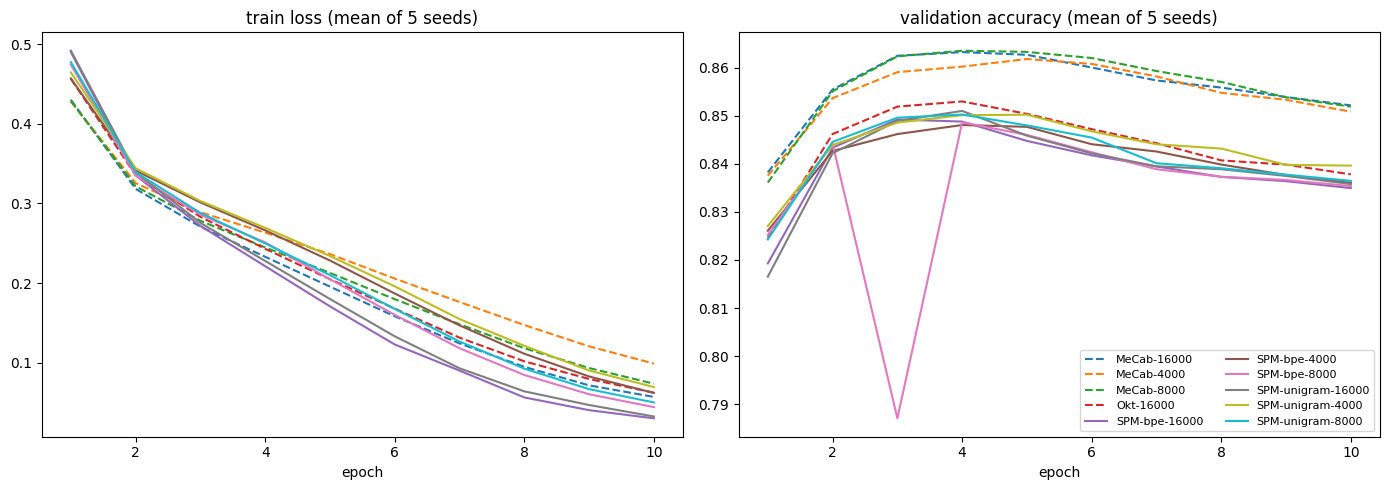

에폭별 검증 정확도 최고 지점(평균 곡선 기준):
        tokenizer  epoch  val_acc
      MeCab-16000      4   0.8632
       MeCab-4000      5   0.8618
       MeCab-8000      4   0.8635
        Okt-16000      4   0.8529
    SPM-bpe-16000      3   0.8492
     SPM-bpe-4000      4   0.8481
     SPM-bpe-8000      4   0.8486
SPM-unigram-16000      4   0.8510
 SPM-unigram-4000      5   0.8502
 SPM-unigram-8000      4   0.8502


In [15]:
hist = pd.DataFrame([dict(h, tokenizer=r['tokenizer'], seed=r['seed']) for r in RESULTS for h in r['hist']])
curve = hist.groupby(['tokenizer', 'epoch'])[['train_loss', 'val_acc']].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, g in curve.groupby('tokenizer'):
    style = '-' if name.startswith('SPM') else '--'
    axes[0].plot(g['epoch'], g['train_loss'], style, label=name)
    axes[1].plot(g['epoch'], g['val_acc'], style, label=name)
axes[0].set_title('train loss (mean of 5 seeds)'); axes[0].set_xlabel('epoch')
axes[1].set_title('validation accuracy (mean of 5 seeds)'); axes[1].set_xlabel('epoch')
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

print('에폭별 검증 정확도 최고 지점(평균 곡선 기준):')
print(curve.loc[curve.groupby('tokenizer')['val_acc'].idxmax(), ['tokenizer', 'epoch', 'val_acc']].round(4).to_string(index=False))

## [개인 실험] 7. 같은 vocab 크기에서 비교

family,MeCab,SPM-bpe,SPM-unigram
vocab,,,
4000,0.8599,0.8493,0.8486
8000,0.8620,0.8500,0.8479
16000,0.8625,0.8462,0.8469


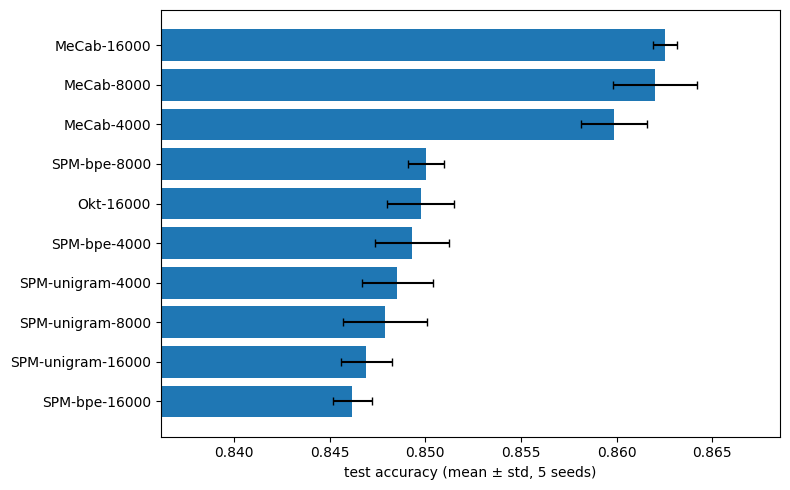

In [16]:
cmp = summary[summary.index.str.match(r'(SPM-unigram|SPM-bpe|MeCab)-')].copy()
cmp['family'] = cmp.index.str.rsplit('-', n=1).str[0]
cmp['vocab'] = cmp.index.str.rsplit('-', n=1).str[1].astype(int)
display(cmp.pivot(index='vocab', columns='family', values='test_mean').round(4))

order = summary.sort_values('test_mean').index
plt.figure(figsize=(8, 5))
plt.barh(order, summary.loc[order, 'test_mean'], xerr=summary.loc[order, 'test_std'], capsize=3)
plt.xlim(summary['test_mean'].min() - 0.01, summary['test_mean'].max() + 0.006)
plt.xlabel('test accuracy (mean ± std, 5 seeds)')
plt.tight_layout(); plt.show()

## [개인 실험] 8. before/after: MAX_LEN 60 → 128

vocab이 작을수록 문장이 잘게 쪼개져 60토큰에서 잘리는 비율이 늘어난다. 잘린 탓에 손해를 봤는지 확인하려고, **다른 조건은 그대로 두고 MAX_LEN만 128로 바꿔** 다시 학습했다. 대상은 잘리는 비율이 가장 큰 SentencePiece 설정과 형태소 최고 설정이다(시드 5개).

In [17]:
spm_names = [n for n in TOK if n.startswith('SPM')]
targets = [token_stats.loc[spm_names, 'cut_ratio'].idxmax(), best_morph]
rows = []
for name in targets:
    t = TOK[name]
    X128 = {k: to_tensor(v, 128) for k, v in t['ids'].items()}
    for seed in SEEDS:
        r = run(X128, labels, t['vocab_size'], seed)
        rows.append(dict(tokenizer=name, seed=seed, val_acc=r['val_acc'], test_acc=r['test_acc']))
        print(name, seed, f"val {r['val_acc']:.4f} test {r['test_acc']:.4f}")
after = pd.DataFrame(rows).groupby('tokenizer')[['val_acc', 'test_acc']].agg(['mean', 'std'])
before = df[df.tokenizer.isin(targets)].groupby('tokenizer')[['val_acc', 'test_acc']].agg(['mean', 'std'])
display(pd.concat({'MAX_LEN=60 (before)': before, 'MAX_LEN=128 (after)': after}, axis=1).round(4))
display(token_stats.loc[targets, ['avg_tokens', 'p95_tokens', 'cut_ratio']].round(4))

SPM-unigram-4000 0 val 0.8511 test 0.8480
SPM-unigram-4000 1 val 0.8559 test 0.8497
SPM-unigram-4000 2 val 0.8533 test 0.8493
SPM-unigram-4000 3 val 0.8529 test 0.8504
SPM-unigram-4000 4 val 0.8507 test 0.8506
MeCab-8000 0 val 0.8647 test 0.8640
MeCab-8000 1 val 0.8621 test 0.8612
MeCab-8000 2 val 0.8654 test 0.8624
MeCab-8000 3 val 0.8655 test 0.8647
MeCab-8000 4 val 0.8677 test 0.8640


MAX_LEN=60 (before)                           \
                             val_acc         test_acc           
                                mean     std     mean     std   
tokenizer                                                       
MeCab-8000                    0.8647  0.0017   0.8620  0.0022   
SPM-unigram-4000              0.8514  0.0013   0.8486  0.0018   

                 MAX_LEN=128 (after)                           
                             val_acc         test_acc          
                                mean     std     mean     std  
tokenizer                                                      
MeCab-8000                    0.8651  0.0020   0.8633  0.0014  
SPM-unigram-4000              0.8528  0.0021   0.8496  0.0011

,avg_tokens,p95_tokens,cut_ratio
tokenizer,,,
SPM-unigram-4000,20.2035,61.0,0.0506
MeCab-8000,18.7179,56.0,0.0397


## [개인 실험] 9. 오답 분석: 형태소 최고 vs SentencePiece 최고 (시드 0)

한쪽만 맞힌 테스트 리뷰를 뽑아, 두 토크나이저가 문장을 어떻게 나눴는지 나란히 본다.

In [18]:
pred = {r['tokenizer']: r['te_pred'] for r in RESULTS if r['seed'] == 0}
y = labels['test']
a_ok, b_ok = pred[best_morph] == y, pred[best_spm] == y
print(f'둘 다 맞힘 {np.mean(a_ok & b_ok):.3f} / {best_morph}만 맞힘 {np.mean(a_ok & ~b_ok):.3f} / '
      f'{best_spm}만 맞힘 {np.mean(~a_ok & b_ok):.3f} / 둘 다 틀림 {np.mean(~a_ok & ~b_ok):.3f}')

def show(mask, title, n=6):
    idx = np.where(mask)[0]
    rng = np.random.default_rng(0)
    pick = rng.choice(idx, size=min(n, len(idx)), replace=False)
    print(f'\n■ {title} ({len(idx)}개 중 {len(pick)}개)')
    out = pd.DataFrame({'리뷰': [texts['test'][i] for i in pick],
                        '정답': ['긍정' if y[i] else '부정' for i in pick],
                        best_morph: [' / '.join(TOK[best_morph]['pieces'](texts['test'][i])) for i in pick],
                        best_spm: [' / '.join(TOK[best_spm]['pieces'](texts['test'][i])) for i in pick]})
    display(out)

show(a_ok & ~b_ok, f'{best_morph}만 맞힌 리뷰')
show(~a_ok & b_ok, f'{best_spm}만 맞힌 리뷰')

lens = np.array([len(t) for t in texts['test']])
for lo, hi in [(0, 10), (10, 30), (30, 60), (60, 200)]:
    m = (lens >= lo) & (lens < hi)
    print(f'글자 수 {lo:3d}~{hi:3d} ({m.sum():5d}개)  {best_morph} {a_ok[m].mean():.4f}  {best_spm} {b_ok[m].mean():.4f}')

둘 다 맞힘 0.791 / MeCab-8000만 맞힘 0.071 / SPM-unigram-16000만 맞힘 0.054 / 둘 다 틀림 0.083

■ MeCab-8000만 맞힌 리뷰 (3486개 중 6개)


,리뷰,정답,MeCab-8000,SPM-unigram-16000
0,어쩌면 좋냐....,부정,어쩌면 / 좋 / 냐 / . / ...,▁어쩌면 / ▁좋 / 냐 / ....
1,영화관에 보러갔었는데 시간도 못죽였었음...레알...보고나서 너무 빡쳐서 집엘 못가겠더라. 그날 결국 박물관이 살아있다까지 보고옴,부정,영화관 / 에 / 보 / 러 / 갔었 / 는데 / 시간 / 도 / 못 / 죽 / 였었 / 음 / . / .. / 레알 / . / .. / 보 / 고 / 나 / 서 / 너무 / 빡 / 쳐서 / 집 / 엘 / 못...,▁영화관에 / ▁보러 / 갔 / 었는데 / ▁시간 / 도 / ▁못 / 죽 / 였 / 었음 / ... / 레알 / ... / 보고나서 / ▁너무 / ▁빡쳐서 / ▁집 / 엘 / ▁못 / 가 / 겠 / 더라 / ...
2,영화 좋구만 평점 왜이네 초딩들이 평점주었나 ..평점 믿지 마세요 영화 강추 ~ 강추,긍정,영화 / 좋 / 구만 / 평점 / 왜 / 이 / 네 / 초딩 / 들 / 이 / 평점 / 주 / 었 / 나 / . / . / 평점 / 믿 / 지 / 마세요 / 영화 / 강추 / ~ / 강추,▁영화 / ▁좋구 / 만 / ▁평점 / ▁왜 / 이네 / ▁초딩 / 들이 / ▁평점 / 주 / 었나 / ▁ / .. / 평점 / ▁믿지 / ▁마세요 / ▁영화 / ▁강추 / ▁ / ~ / ▁강추
3,보고나면 얼굴근육이 다 욱씬거린다.,긍정,보 / 고 / 나 / 면 / 얼굴 / 근육 / 이 / 다 / 욱 / 씬 / 거린다 / .,▁보고나면 / ▁얼굴 / 근 / 육 / 이 / ▁다 / ▁ / 욱 / 씬 / 거 / 린다 / .
4,분위기론드라마는만들어지지않는다내용에충실했으면...,부정,분위기 / 론 / 드라마 / 는 / 만들 / 어 / 지 / 지 / 않 / 는다 / 내용 / 에 / 충실 / 했으면 / . / ..,▁분위기 / 론 / 드라마 / 는 / 만들어 / 지 / 지않는다 / 내용 / 에 / 충 / 실 / 했으면 / ...
5,쥬라기 공원도 나오는데 인디아나 존스5의 소식은 왜 잠잠한가요?,긍정,쥬라기 / 공원 / 도 / 나오 / 는데 / 인디아나 / 존스 / 5 / 의 / 소식 / 은 / 왜 / 잠잠 / 한가요 / ?,▁쥬라기 / ▁공 / 원 / 도 / ▁나오는데 / ▁인디아나 / ▁존스 / 5 / 의 / ▁소 / 식 / 은 / ▁왜 / ▁잠 / 잠 / 한 / 가요 / ?



■ SPM-unigram-16000만 맞힌 리뷰 (2673개 중 6개)


,리뷰,정답,MeCab-8000,SPM-unigram-16000
0,연륜이있어야보이는홍상수형님의영화는무얼먹으면서보아야제일맛있을까?,긍정,연륜 / 이 / 있 / 어야 / 보이 / 는 / 홍상 / 수형 / 님 / 의 / 영화 / 는 / 무얼 / 먹 / 으면서 / 보 / 아야 / 제일 / 맛있 / 을까 / ?,▁연 / 륜 / 이 / 있어야 / 보이는 / 홍 / 상 / 수 / 형님 / 의 / 영화는 / 무 / 얼 / 먹으면서 / 보 / 아 / 야 / 제일 / 맛 / 있을까 / ?
1,자꾸 이상한 생각하게 만든다구 Boy♂,긍정,자꾸 / 이상 / 한 / 생각 / 하 / 게 / 만든 / 다구 / Boy / ♂,▁자꾸 / ▁이상한 / ▁생각하게 / ▁만든다 / 구 / ▁B / o / y / ♂
2,그 옛날 티 비에서 재방영 할때 봣던 영화,긍정,그 / 옛날 / 티 / 비 / 에서 / 재 / 방영 / 할 / 때 / 봣던 / 영화,▁그 / ▁옛날 / ▁티 / ▁비 / 에서 / ▁재방 / 영 / ▁할때 / ▁ / 봣던 / ▁영화
3,패스트 정크 푸드를 먹고 자란 우리네 감성,긍정,패스트 / 정크 / 푸드 / 를 / 먹 / 고 / 자란 / 우리 / 네 / 감성,▁패 / 스트 / ▁정 / 크 / ▁푸 / 드 / 를 / ▁먹고 / ▁자 / 란 / ▁우리네 / ▁감성
4,"눈째고 코올리고 가슴에 플라스틱 열라 넣은 성형괴물 곽지민이 매력있다고 하는 사람들이 있는걸 보니 대한민국 영화는 미래가 별로 없어보이네, 왜 성형괴물들은 웃으면 코와 입이 부자연스럽게 일그러지는지, 정말 혐...",부정,눈 / 째 / 고 / 코 / 올리 / 고 / 가슴 / 에 / 플라스틱 / 열라 / 넣 / 은 / 성형 / 괴물 / 곽지민 / 이 / 매력 / 있 / 다고 / 하 / 는 / 사람 / 들 / 이 / 있 / 는 /...,▁눈 / 째 / 고 / ▁코 / 올리 / 고 / ▁가슴에 / ▁ / 플 / 라 / 스틱 / ▁열라 / ▁넣은 / ▁성형 / 괴물 / ▁곽지민 / 이 / ▁매력있다 / 고 / ▁하는 / ▁사람들이 / ▁있는 /...
5,"영화 몰입도도 좋고 후반부로 갈수록 긴장감과 리얼리티는 끝장이다 그러나 참을수없는 불쾌함과 분노만이...,,.,,,.......ㅡㅡ",부정,영화 / 몰입 / 도 / 도 / 좋 / 고 / 후반부 / 로 / 갈수록 / 긴장감 / 과 / 리얼리티 / 는 / 끝장 / 이 / 다 / 그러나 / 참 / 을 / 수 / 없 / 는 / 불쾌 / 함 / 과 / 분...,▁영화 / ▁몰입도도 / ▁좋고 / ▁후반부로 / ▁갈수록 / ▁긴장감과 / ▁리얼리티 / 는 / ▁끝장 / 이다 / ▁그러나 / ▁참 / 을 / 수없는 / ▁불쾌함 / 과 / ▁분노 / 만이 / ... / ...


글자 수   0~ 10 ( 3512개)  MeCab-8000 0.8727  SPM-unigram-16000 0.8551
글자 수  10~ 30 (23323개)  MeCab-8000 0.8545  SPM-unigram-16000 0.8381
글자 수  30~ 60 (15206개)  MeCab-8000 0.8639  SPM-unigram-16000 0.8453
글자 수  60~200 ( 7116개)  MeCab-8000 0.8797  SPM-unigram-16000 0.8673


## [추가 실험] Kkma 형태소 분석기 비교

과제 안내의 "KoNLPy에 있는 Mecab, kkma, Okt 등과 비교해보세요"에서 위 실험에서 빠졌던 Kkma를 채운다.

**질문:** Kkma는 실제로 얼마나 느린가? 감정 분석 성능은 MeCab·Okt·SentencePiece와 비교해 어느 정도인가?

**조건은 위 실험과 같다:** NSMC 전체, 검증 10% 분리(`random_state=42`), MAX_LEN 60, BiLSTM(임베딩 128, 은닉 128), 10에폭 중 최고 검증 에폭으로 테스트 1회, 시드 5개. vocab은 학습 데이터 빈도순으로 자르고(0=pad, 1=unk), Okt와 같은 16000과 MeCab 최고 설정과 같은 8000 두 가지로 본다.

이 섹션은 위 셀과 따로 실행할 수 있게 만들었다. 데이터 분할을 같은 방법으로 다시 만들고, 위 실험을 다시 돌리지 않고 별도 Colab 세션(A100 80GB, CPU 12코어)에서 실행했다. 같은 내용은 `SentencePiece_추가실험_Kkma.ipynb`에도 있다.

### 설치 (konlpy, Kkma용 Java)

In [1]:
!pip install -q konlpy
!java -version 2>/dev/null || (apt-get -qq update > /dev/null && apt-get -qq install -y default-jdk-headless > /dev/null && echo "java installed")

[0.028s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.028s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


### 데이터 (v2와 같은 분할)

In [2]:
import os, random, copy, time, json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device, torch.cuda.get_device_name(0) if device == 'cuda' else '', '/ CPU 코어', os.cpu_count())

SEEDS = [0, 1, 2, 3, 4]
EPOCHS = 10
MAX_LEN = 60
BATCH = 256

!wget -q -nc https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
!wget -q -nc https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt

def load(path):
    df = pd.read_table(path).dropna().drop_duplicates(subset=['document'])
    df['document'] = df['document'].str.replace('\n', ' ')
    return df[df['document'].str.strip() != ''].reset_index(drop=True)

train_all = load('ratings_train.txt')
test_df = load('ratings_test.txt')
val_df = train_all.groupby('label', group_keys=False).sample(frac=0.1, random_state=42)
train_df = train_all.drop(val_df.index)
texts = {'train': train_df['document'].tolist(), 'val': val_df['document'].tolist(), 'test': test_df['document'].tolist()}
labels = {'train': train_df['label'].values, 'val': val_df['label'].values, 'test': test_df['label'].values}
for k in texts:
    print(f'{k:5s} {len(texts[k]):7,d}개  긍정 비율 {labels[k].mean():.3f}')
N_TOTAL = sum(len(v) for v in texts.values())

cuda NVIDIA A100-SXM4-80GB / CPU 코어 12
train 131,564개  긍정 비율 0.498
val    14,618개  긍정 비율 0.498
test   49,157개  긍정 비율 0.503


### 1. 속도 측정

검증 리뷰 1,000개를 한 프로세스에서 Kkma로 분석해 시간을 재고, 전체(약 19.5만 개)로 환산한다. v2에서 잰 시간은 MeCab 13초, Okt 742초다.

In [3]:
from konlpy.tag import Kkma
kkma = Kkma()
kkma.morphs('워밍업 문장입니다.')

sample = texts['val'][:1000]
t0 = time.time()
sample_morphs = [kkma.morphs(t) for t in sample]
per_sent = (time.time() - t0) / len(sample)

est_single = per_sent * N_TOTAL
workers = max(1, (os.cpu_count() or 2) - 1)
print(f'1,000개 {per_sent * 1000:.1f}초 → 1개당 {per_sent * 1000:.1f}ms')
print(f'전체 {N_TOTAL:,}개 예상: 1프로세스 {est_single / 60:.0f}분 / {workers}프로세스 병렬 약 {est_single / workers / 60:.0f}분')
print(f'Okt(742초) 대비 약 {est_single / 742:.1f}배, MeCab(13초) 대비 약 {est_single / 13:.0f}배')
for t, m in list(zip(sample, sample_morphs))[:3]:
    print(t, '→', ' / '.join(m))

1,000개 23.7초 → 1개당 23.7ms
전체 195,339개 예상: 1프로세스 77분 / 11프로세스 병렬 약 7분
Okt(742초) 대비 약 6.2배, MeCab(13초) 대비 약 356배
설정이 복잡하고 캐릭터가 죽어 있어 마지막 전에 질린다 → 설정 / 이 / 복잡 / 하 / 고 / 캐릭터 / 가 / 죽 / 어 / 있 / 어 / 마지막 / 전 / 에 / 질리 / ㄴ다
줄거리 진짜 꽝... 슈퍼가 보는맛에 버텼다... → 줄거리 / 진짜 / 꽝 / ... / 슈퍼 / 가 / 보 / 는 / 맛 / 에 / 버티 / 었 / 다 / ...
영화가 끝나갈무렵 범이가 칼맞고 쓰러졋을때 수경이가 발로 찾을때... 난 그장면이 제일 임팩트 잇는것같다! → 영화 / 가 / 끝나가 / ㄹ / 무렵 / 범 / 이 / 가 / 아 / 칼 / 맞 / 고 / 쓰 / 러 / 졋 / 을 / 때 / 수경 / 이 / 가 / 아 / 발 / 로 / 찾 / 을 / 때 / ... / 나 / 는 / 그 / 장면 / 이 / 제일 / 임팩트 / 잇 / 는 / 것 / 같 / 다 / !


### 2. 전체 형태소 분석 (병렬)

프로세스마다 Kkma(와 JVM)를 따로 띄운다. 이미 JVM이 뜬 프로세스를 복제(fork)하면 멈출 수 있어서 `spawn` 방식으로 새로 띄운다. 분석에 실패한 문장은 공백 기준으로 대신 나누고 개수를 센다. 끝나면 결과를 `kkma_morphs.pkl`로 저장해, 런타임이 살아 있으면 다시 돌려도 분석을 건너뛴다.

In [4]:
%%writefile kkma_worker.py
from konlpy.tag import Kkma

_kkma = None

def init():
    global _kkma
    _kkma = Kkma()

def morphs_batch(batch):
    out, failed = [], 0
    for t in batch:
        try:
            out.append(_kkma.morphs(t))
        except Exception:
            out.append(t.split())
            failed += 1
    return out, failed

Writing kkma_worker.py


In [5]:
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
import kkma_worker

CACHE = 'kkma_morphs.pkl'
if os.path.exists(CACHE):
    MORPH = pickle.load(open(CACHE, 'rb'))
    print('저장된 분석 결과를 불러왔다:', {k: len(v) for k, v in MORPH.items()})
else:
    CHUNK = 500
    MORPH, failed_total = {}, 0
    t_all = time.time()
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context('spawn'), initializer=kkma_worker.init) as ex:
        for k, v in texts.items():
            chunks = [v[i:i + CHUNK] for i in range(0, len(v), CHUNK)]
            out = []
            for j, (res, failed) in enumerate(ex.map(kkma_worker.morphs_batch, chunks), 1):
                out.extend(res)
                failed_total += failed
                if j % 20 == 0 or j == len(chunks):
                    print(f'{k:5s} {min(j * CHUNK, len(v)):7,d}/{len(v):,}  경과 {(time.time() - t_all) / 60:.1f}분', flush=True)
            MORPH[k] = out
    elapsed = time.time() - t_all
    print(f'Kkma 형태소 분석 {elapsed:.0f}초 ({elapsed / 60:.1f}분, {workers}프로세스), 실패해서 공백으로 나눈 문장 {failed_total}개')
    pickle.dump(MORPH, open(CACHE, 'wb'))
assert all(len(MORPH[k]) == len(texts[k]) for k in texts)

train  10,000/131,564  경과 3.1분
train  20,000/131,564  경과 3.1분
train  30,000/131,564  경과 3.1분
train  40,000/131,564  경과 14.7분
train  50,000/131,564  경과 14.7분
train  60,000/131,564  경과 14.7분
train  70,000/131,564  경과 14.7분
train  80,000/131,564  경과 14.7분
train  90,000/131,564  경과 14.7분
train 100,000/131,564  경과 14.7분
train 110,000/131,564  경과 14.7분
train 120,000/131,564  경과 14.7분
train 130,000/131,564  경과 14.7분
train 131,564/131,564  경과 14.7분
val    10,000/14,618  경과 21.0분
val    14,618/14,618  경과 21.0분
test   10,000/49,157  경과 21.7분
test   20,000/49,157  경과 22.4분
test   30,000/49,157  경과 24.3분
test   40,000/49,157  경과 35.8분
test   49,157/49,157  경과 35.8분
Kkma 형태소 분석 2150초 (35.8분, 11프로세스), 실패해서 공백으로 나눈 문장 5개


### 3. 단어 사전과 토큰 통계

In [6]:
def to_tensor(id_lists, max_len):
    seqs = [torch.tensor(ids[:max_len] or [1], dtype=torch.long) for ids in id_lists]
    return pad_sequence(seqs, batch_first=True, padding_value=0)

cnt = Counter(w for ts in MORPH['train'] for w in ts)
print(f'Kkma 학습 데이터 고유 형태소 {len(cnt):,}개')

TOK, rows = {}, []
for vs in [8000, 16000]:
    word_index = {w: i + 2 for i, (w, _) in enumerate(cnt.most_common(vs - 2))}
    ids = {k: [[word_index.get(w, 1) for w in ts] for ts in v] for k, v in MORPH.items()}
    TOK[f'Kkma-{vs}'] = dict(X={k: to_tensor(v, MAX_LEN) for k, v in ids.items()}, vocab_size=vs)
    lens = np.array([len(x) for x in ids['train']])
    va_total = sum(len(x) for x in ids['val'])
    rows.append(dict(tokenizer=f'Kkma-{vs}', avg_tokens=lens.mean(), p95_tokens=np.percentile(lens, 95),
                     cut_ratio=(lens > MAX_LEN).mean(), unk_val=sum(x.count(1) for x in ids['val']) / va_total))
display(pd.DataFrame(rows).set_index('tokenizer').round(4))
print('v2 참고: MeCab avg_tokens 18.72 / cut 0.0397 / unk_val 0.0463(8000)·0.0258(16000), Okt-16000 14.67 / 0.0047 / 0.0805')

for t in texts['val'][:3]:
    print(t, '→', ' / '.join(MORPH['val'][texts['val'].index(t)]))

Kkma 학습 데이터 고유 형태소 40,895개


,avg_tokens,p95_tokens,cut_ratio,unk_val
tokenizer,,,,
Kkma-8000,20.2516,61.0,0.0501,0.0320
Kkma-16000,20.2516,61.0,0.0501,0.0156


v2 참고: MeCab avg_tokens 18.72 / cut 0.0397 / unk_val 0.0463(8000)·0.0258(16000), Okt-16000 14.67 / 0.0047 / 0.0805
설정이 복잡하고 캐릭터가 죽어 있어 마지막 전에 질린다 → 설정 / 이 / 복잡 / 하 / 고 / 캐릭터 / 가 / 죽 / 어 / 있 / 어 / 마지막 / 전 / 에 / 질리 / ㄴ다
줄거리 진짜 꽝... 슈퍼가 보는맛에 버텼다... → 줄거리 / 진짜 / 꽝 / ... / 슈퍼 / 가 / 보 / 는 / 맛 / 에 / 버티 / 었 / 다 / ...
영화가 끝나갈무렵 범이가 칼맞고 쓰러졋을때 수경이가 발로 찾을때... 난 그장면이 제일 임팩트 잇는것같다! → 영화 / 가 / 끝나가 / ㄹ / 무렵 / 범 / 이 / 가 / 아 / 칼 / 맞 / 고 / 쓰 / 러 / 졋 / 을 / 때 / 수경 / 이 / 가 / 아 / 발 / 로 / 찾 / 을 / 때 / ... / 나 / 는 / 그 / 장면 / 이 / 제일 / 임팩트 / 잇 / 는 / 것 / 같 / 다 / !


### 4. 학습 (v2와 같은 모델·학습 방법)

In [7]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden=128):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden * 2, 1)

    def forward(self, x):
        out, _ = self.lstm(self.emb(x))
        mask = (x != 0).unsqueeze(-1).float()
        pooled = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.fc(pooled).squeeze(-1)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

@torch.no_grad()
def predict(model, X, bs=4096):
    model.eval()
    return torch.cat([(model(X[i:i + bs]) > 0).long().cpu() for i in range(0, len(X), bs)]).numpy()

def run(X, y, vocab_size, seed, epochs=EPOCHS, bs=BATCH):
    set_seed(seed)
    Xtr, Xva, Xte = X['train'].to(device), X['val'].to(device), X['test'].to(device)
    ytr = torch.tensor(y['train'], dtype=torch.float, device=device)
    model = LSTMClassifier(vocab_size).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.BCEWithLogitsLoss()
    g = torch.Generator().manual_seed(seed)
    hist, best_acc, best_state, best_ep = [], -1, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=g).to(device)
        total = 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        va_acc = (predict(model, Xva) == y['val']).mean()
        hist.append(dict(epoch=ep, train_loss=total / len(Xtr), val_acc=va_acc))
        if va_acc > best_acc:
            best_acc, best_state, best_ep = va_acc, copy.deepcopy(model.state_dict()), ep
    model.load_state_dict(best_state)
    te_pred = predict(model, Xte)
    return dict(seed=seed, best_ep=best_ep, val_acc=best_acc, test_acc=(te_pred == y['test']).mean(), hist=hist)

RESULTS = []
for name, t in TOK.items():
    for seed in SEEDS:
        t0 = time.time()
        r = run(t['X'], labels, t['vocab_size'], seed)
        r['tokenizer'] = name
        RESULTS.append(r)
        print(f"{name:10s} seed {seed}  best_ep {r['best_ep']:2d}  val {r['val_acc']:.4f}  test {r['test_acc']:.4f}  ({time.time() - t0:.0f}s)")
json.dump(RESULTS, open('results_kkma.json', 'w'), default=float)

Kkma-8000  seed 0  best_ep  4  val 0.8669  test 0.8622  (31s)
Kkma-8000  seed 1  best_ep  4  val 0.8620  test 0.8616  (19s)
Kkma-8000  seed 2  best_ep  7  val 0.8644  test 0.8578  (19s)
Kkma-8000  seed 3  best_ep  4  val 0.8642  test 0.8625  (19s)
Kkma-8000  seed 4  best_ep  6  val 0.8622  test 0.8596  (19s)
Kkma-16000 seed 0  best_ep  4  val 0.8669  test 0.8627  (19s)
Kkma-16000 seed 1  best_ep  4  val 0.8637  test 0.8613  (19s)
Kkma-16000 seed 2  best_ep  5  val 0.8620  test 0.8609  (19s)
Kkma-16000 seed 3  best_ep  5  val 0.8642  test 0.8625  (19s)
Kkma-16000 seed 4  best_ep  5  val 0.8626  test 0.8607  (19s)


### 5. 위 실험 결과와 비교 (시드 5개 평균 ± 표준편차)

,val_mean,val_std,test_mean,test_std,best_ep,출처
tokenizer,,,,,,
MeCab-8000,0.8647,0.0017,0.8620,0.0022,4.2,v2
MeCab-16000,0.8640,0.0024,0.8625,0.0006,4.8,v2
Kkma-8000,0.8639,0.0020,0.8607,0.0020,5.0,이번 실행
Kkma-16000,0.8639,0.0019,0.8616,0.0009,4.6,이번 실행
Okt-16000,0.8532,0.0012,0.8498,0.0017,3.8,v2
SPM-unigram-16000,0.8515,0.0006,0.8469,0.0013,3.8,v2


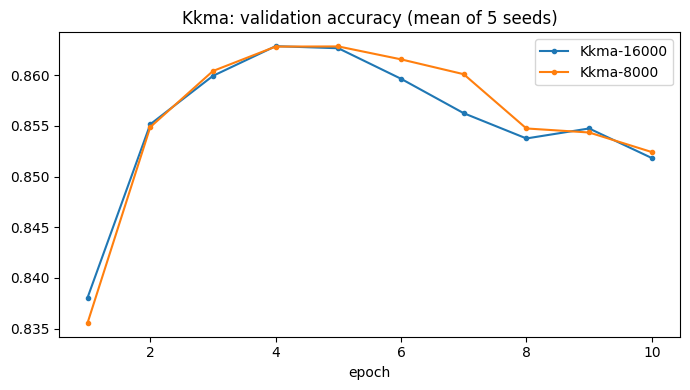

In [8]:
df = pd.DataFrame([{k: v for k, v in r.items() if k != 'hist'} for r in RESULTS])
kkma_summary = df.groupby('tokenizer').agg(val_mean=('val_acc', 'mean'), val_std=('val_acc', 'std'),
                                           test_mean=('test_acc', 'mean'), test_std=('test_acc', 'std'),
                                           best_ep=('best_ep', 'mean'))
v2 = pd.DataFrame([
    ('MeCab-8000',        0.8647, 0.0017, 0.8620, 0.0022, 4.2),
    ('MeCab-16000',       0.8640, 0.0024, 0.8625, 0.0006, 4.8),
    ('Okt-16000',         0.8532, 0.0012, 0.8498, 0.0017, 3.8),
    ('SPM-unigram-16000', 0.8515, 0.0006, 0.8469, 0.0013, 3.8),
], columns=['tokenizer', 'val_mean', 'val_std', 'test_mean', 'test_std', 'best_ep']).set_index('tokenizer')
compare = pd.concat([kkma_summary, v2]).sort_values('val_mean', ascending=False)
compare['출처'] = ['이번 실행' if i.startswith('Kkma') else 'v2' for i in compare.index]
display(compare.round(4))

hist = pd.DataFrame([dict(h, tokenizer=r['tokenizer'], seed=r['seed']) for r in RESULTS for h in r['hist']])
curve = hist.groupby(['tokenizer', 'epoch'])['val_acc'].mean().reset_index()
plt.figure(figsize=(7, 4))
for name, g in curve.groupby('tokenizer'):
    plt.plot(g['epoch'], g['val_acc'], marker='o', ms=3, label=name)
plt.title('Kkma: validation accuracy (mean of 5 seeds)')
plt.xlabel('epoch')
plt.legend()
plt.tight_layout()
plt.show()

### 결과 해석

| 토크나이저 | 검증 | 테스트 | 최고 에폭 | 문장당 토큰 | `<unk>`(검증) | 형태소 분석 시간 |
|---|---|---|---|---|---|---|
| MeCab-8000 (v2) | **0.8647 ± 0.0017** | 0.8620 ± 0.0022 | 4.2 | 18.7 | 4.6% | 13초 |
| MeCab-16000 (v2) | 0.8640 ± 0.0024 | **0.8625 ± 0.0006** | 4.8 | 18.7 | 2.6% | 13초 |
| **Kkma-8000** | 0.8639 ± 0.0020 | 0.8607 ± 0.0020 | 5.0 | 20.3 | 3.2% | 2,150초 (11프로세스) |
| **Kkma-16000** | 0.8639 ± 0.0019 | 0.8616 ± 0.0009 | 4.6 | 20.3 | 1.6% | 〃 |
| Okt-16000 (v2) | 0.8532 ± 0.0012 | 0.8498 ± 0.0017 | 3.8 | 14.7 | 8.1% | 742초 |
| SPM-unigram-16000 (v2) | 0.8515 ± 0.0006 | 0.8469 ± 0.0013 | 3.8 | 15.4 | 0.1% | SPM 6개 학습·인코딩 합계 96초 |

- **정확도는 MeCab과 거의 같다.** 검증 0.8639로 MeCab-8000(0.8647)보다 0.08%p 낮을 뿐이다. 이 차이는 시드 표준편차(0.17~0.24%p)보다 작다. Okt(0.8532)나 SentencePiece(0.8515)보다는 1%p 넘게 높다.
- **대신 매우 느리다.** 1,000개로 재면 1개당 23.7ms로, 한 프로세스로는 전체 약 77분이다(MeCab의 약 356배, Okt의 약 6.2배). 11프로세스 병렬로 돌렸는데도 실제로는 35.8분이 걸렸다. 속도 측정으로 낸 예상(7분)보다 5배 느렸다. 진행 기록을 보면 중간에 10분 넘게 멈춘 구간이 있었는데, 특정 문장에서 오래 걸린 것인지는 확인하지 못했다. 분석에 실패한 문장은 5개였다(공백으로 대신 나눔).
- **가장 잘게 나눈다.** 문장당 20.3토큰으로 MeCab(18.7)보다 많다. `버텼다`를 `버티 / 었 / 다`로, `질린다`를 `질리 / ㄴ다`로 나누는 것처럼 활용된 말을 기본형과 어미로 되돌린다.
- **잘게 나누는 것보다 "어디서" 나누는지가 중요해 보인다.** 어간과 어미를 떼어 내는 MeCab·Kkma는 0.864 근처였다. 반면 `복잡하고`, `버텼다`처럼 붙여 두는 Okt와, `▁복잡 / 하고`처럼 나누는 SentencePiece(unigram-8000 예시)는 0.85 근처였다. 그런데 SPM-unigram-4000도 문장당 20.2토큰으로 Kkma만큼 잘게 나누지만 검증 0.8514에 그쳤다. 토큰 수가 아니라 형태소 경계에서 나누는지가 차이를 만든 것으로 보인다(모델 하나로 본 상관관계라 단정하지는 않는다).

## [선택 과제] fastText 사전학습 단어 벡터로 임베딩 초기화

5단계 과제 안내의 선택 항목이다: *"fasttext로 사전훈련된 Word Vector를 사용할 수 있지만 … 기본적인 태스크를 끝나고 도전하시는걸 추천합니다."*

**질문:** 임베딩을 무작위로 시작하는 대신 fastText 한국어 사전학습 벡터(`cc.ko.300`, Common Crawl + Wikipedia)로 시작하면 성능이 오를까? SentencePiece와 MeCab 중 어느 쪽이 더 덕을 볼까?

**조건은 위 실험과 똑같이 맞췄다:** NSMC 전체, 검증 10% 분리(`random_state=42`), MAX_LEN 60, BiLSTM(은닉 128), 10에폭 중 최고 검증 에폭으로 테스트 1회, 시드 5개. 토크나이저는 v2의 형태소 최고 **MeCab-8000**과 SentencePiece 최고 **SPM-unigram-16000**이다(둘 다 검증 기준).

| 임베딩 설정 | 차원 | 초기값 | 학습 중 |
|---|---|---|---|
| `random-128` | 128 | 무작위 | 학습 (v2와 같은 설정, 재현 확인용) |
| `random-300` | 300 | 무작위 | 학습 (차원만 키운 대조군) |
| `fasttext-300` | 300 | fastText | 학습 (미세조정) |
| `fasttext-300-frozen` | 300 | fastText | 고정 |

`random-300`을 둔 이유: fastText는 300차원이라, 그냥 비교하면 "사전학습 덕분"인지 "차원이 커져서"인지 구분할 수 없다.

이 섹션은 위 셀과 따로 실행할 수 있게 만들었다. 데이터 분할과 두 토크나이저를 같은 방법으로 다시 만들고, 위 실험을 다시 돌리지 않고 별도 Colab 세션(A100 40GB)에서 실행했다. 같은 내용은 `SentencePiece_선택과제_fastText.ipynb`에도 있다.

### 설치 (konlpy, sentencepiece, MeCab, fasttext)

In [7]:
!pip install -q konlpy sentencepiece
%cd /content
!test -d Mecab-ko-for-Google-Colab || git clone -q https://github.com/SOMJANG/Mecab-ko-for-Google-Colab.git
%cd /content/Mecab-ko-for-Google-Colab
!bash install_mecab-ko_on_colab_light_220429.sh > /tmp/mecab_install.log 2>&1; tail -n 3 /tmp/mecab_install.log
%cd /content
!pip install -q fasttext || pip install -q fasttext-wheel

/content
/content/Mecab-ko-for-Google-Colab
블로그에 해결 방법을 남겨주신 tana님 감사합니다.
light 버전 작성 : Dogdriip님 ( https://github.com/Dogdriip )
문제를 해결해주신 combacsa님 감사합니다.
/content


### 데이터와 토크나이저 (v2와 같은 절차)

In [8]:
import os, random, copy, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence
import sentencepiece as spm
from konlpy.tag import Mecab

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device, torch.cuda.get_device_name(0) if device == 'cuda' else '')

SEEDS = [0, 1, 2, 3, 4]
EPOCHS = 10
MAX_LEN = 60
BATCH = 256

!wget -q -nc https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
!wget -q -nc https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt

def load(path):
    df = pd.read_table(path).dropna().drop_duplicates(subset=['document'])
    df['document'] = df['document'].str.replace('\n', ' ')
    return df[df['document'].str.strip() != ''].reset_index(drop=True)

train_all = load('ratings_train.txt')
test_df = load('ratings_test.txt')
val_df = train_all.groupby('label', group_keys=False).sample(frac=0.1, random_state=42)
train_df = train_all.drop(val_df.index)
texts = {'train': train_df['document'].tolist(), 'val': val_df['document'].tolist(), 'test': test_df['document'].tolist()}
labels = {'train': train_df['label'].values, 'val': val_df['label'].values, 'test': test_df['label'].values}
for k in texts:
    print(f'{k:5s} {len(texts[k]):7,d}개  긍정 비율 {labels[k].mean():.3f}')

cuda NVIDIA A100-SXM4-40GB
train 131,564개  긍정 비율 0.498
val    14,618개  긍정 비율 0.498
test   49,157개  긍정 비율 0.503


In [9]:
def sp_tokenize(s, corpus, vocab_path='./korean_spm.vocab', max_len=None):
    tensor = []
    for sen in corpus:
        ids = s.EncodeAsIds(sen)
        if max_len:
            ids = ids[:max_len]
        # 📄 원본: tensor.append(s.EncodeAsIds(sen))
        # 🔧 수정: list → tensor (pad_sequence는 tensor만 받는다)
        tensor.append(torch.tensor(ids, dtype=torch.long))

    with open(vocab_path, 'r', encoding='utf-8') as f:
        vocab = f.readlines()

    word_index = {}
    index_word = {}
    for idx, line in enumerate(vocab):
        word = line.split('\t')[0]
        word_index.update({word: idx})
        index_word.update({idx: word})

    tensor = pad_sequence(tensor, batch_first=True, padding_value=0)
    return tensor, word_index, index_word

def to_tensor(id_lists, max_len):
    seqs = [torch.tensor(ids[:max_len] or [1], dtype=torch.long) for ids in id_lists]
    return pad_sequence(seqs, batch_first=True, padding_value=0)

TOK = {}

# SentencePiece unigram 16000 (v2와 같은 입력·옵션)
with open('nsmc_train_v2.txt', 'w', encoding='utf-8') as f:
    for t in texts['train']:
        f.write(t + '\n')
prefix = 'nsmc_v2_unigram_16000'
spm.SentencePieceTrainer.Train(
    f'--input=nsmc_train_v2.txt --model_prefix={prefix} --vocab_size=16000 '
    f'--model_type=unigram --pad_id=0 --unk_id=1 --bos_id=2 --eos_id=3 --minloglevel=2'
)
sp = spm.SentencePieceProcessor()
sp.Load(f'{prefix}.model')
X = {}
for k, v in texts.items():
    X[k], sp_word_index, sp_index_word = sp_tokenize(sp, v, f'{prefix}.vocab', MAX_LEN)
TOK['SPM-unigram-16000'] = dict(X=X, index_word=sp_index_word, n_special=4)

# MeCab 8000 (v2와 같은 방식: 학습 데이터 빈도순, 0=pad, 1=unk)
mecab = Mecab()
t0 = time.time()
morphs = {k: [mecab.morphs(t) for t in v] for k, v in texts.items()}
print(f'MeCab 형태소 분석 {time.time() - t0:.0f}초')
cnt = Counter(w for ts in morphs['train'] for w in ts)
mecab_word_index = {w: i + 2 for i, (w, _) in enumerate(cnt.most_common(8000 - 2))}
mecab_index_word = {0: '<pad>', 1: '<unk>', **{i: w for w, i in mecab_word_index.items()}}
ids = {k: [[mecab_word_index.get(w, 1) for w in ts] for ts in v] for k, v in morphs.items()}
TOK['MeCab-8000'] = dict(X={k: to_tensor(v, MAX_LEN) for k, v in ids.items()}, index_word=mecab_index_word, n_special=2)

for name, t in TOK.items():
    print(name, 'vocab', len(t['index_word']), {k: tuple(v.shape) for k, v in t['X'].items()})

MeCab 형태소 분석 12초
SPM-unigram-16000 vocab 16000 {'train': (131564, 60), 'val': (14618, 60), 'test': (49157, 60)}
MeCab-8000 vocab 8000 {'train': (131564, 60), 'val': (14618, 60), 'test': (49157, 60)}


### fastText 한국어 벡터 불러오기

`cc.ko.300.bin`은 단어 벡터와 함께 글자 n-gram 벡터를 갖고 있어서, 사전에 없는 토큰도 글자 조각을 합쳐 벡터를 만들 수 있다. SentencePiece 조각의 `▁`(단어 시작 표시)는 떼고 조회한다.

In [10]:
if not os.path.exists('cc.ko.300.bin'):
    !wget -q https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ko.300.bin.gz
    !gunzip -f cc.ko.300.bin.gz
!ls -lh cc.ko.300.bin

import fasttext
t0 = time.time()
ft = fasttext.load_model('cc.ko.300.bin')
print(f'불러오기 {time.time() - t0:.0f}초, 차원 {ft.get_dimension()}, 단어 수 {len(ft.get_words(on_unicode_error="replace")):,}')

-rw-r--r-- 1 root root 6.8G Jan 18  2019 cc.ko.300.bin
불러오기 6초, 차원 300, 단어 수 2,000,000


In [6]:
def build_embedding(index_word, n_special, dim=300, seed=0):
    rng = np.random.default_rng(seed)
    W = np.zeros((len(index_word), dim), dtype=np.float32)
    in_vocab, subword, empty = 0, 0, 0
    for idx in range(len(index_word)):
        if idx == 0:
            continue                                  # <pad>는 0 벡터
        if idx < n_special:
            W[idx] = rng.normal(0, 0.1, dim)          # <unk>, <s>, </s>
            continue
        word = index_word[idx].replace('▁', '')
        if not word:
            W[idx] = rng.normal(0, 0.1, dim)          # '▁' 하나만 있는 조각
            empty += 1
            continue
        W[idx] = ft.get_word_vector(word)
        if ft.get_word_id(word) != -1:
            in_vocab += 1
        else:
            subword += 1
    n = len(index_word) - n_special
    stats = dict(fastText_사전에_있음=in_vocab / n, 글자조각으로_생성=subword / n, 빈_조각=empty / n)
    return torch.tensor(W), stats

EMB, cover = {}, {}
for name, t in TOK.items():
    EMB[name], cover[name] = build_embedding(t['index_word'], t['n_special'])
display(pd.DataFrame(cover).T.round(4))

for name, t in TOK.items():
    words = [t['index_word'][i] for i in range(t['n_special'], t['n_special'] + 12)]
    print(name, '자주 나오는 토큰:', words)
for w in ['재밌', '최고', '노잼', '평점']:
    print(w, '→', [x for _, x in ft.get_nearest_neighbors(w, k=5)])

,fastText_사전에_있음,글자조각으로_생성,빈_조각
SPM-unigram-16000,0.9169,0.0831,0.0001
MeCab-8000,0.9386,0.0614,0.0000


SPM-unigram-16000 자주 나오는 토큰: ['.', '▁', '..', '▁영화', '...', '이', '의', ',', '도', '가', '는', '을']
MeCab-8000 자주 나오는 토큰: ['.', '이', '는', '영화', '다', '고', '하', '도', '의', '가', '은', '에']
재밌 → ['변했', '놀랍', '빛났', '젖혔', '어렸']
최고 → ['最古', '최강에', '最高', '공항상', '권위인']
노잼 → ['꿀잼', '웃김', '열폭', 'ㄹㅇ', '노답']
평점 → ['0.0점', '2.5점', '4.0점', '구매수', '4.3점']


### 학습 함수

v2와 같은 BiLSTM 분류기다. 바뀐 점은 임베딩 차원과 초기값을 고를 수 있다는 것 하나다.

In [11]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden=128, pretrained=None, freeze=False):
        super().__init__()
        if pretrained is None:
            self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        else:
            self.emb = nn.Embedding.from_pretrained(pretrained, freeze=freeze, padding_idx=0)
            emb_dim = pretrained.shape[1]
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden * 2, 1)

    def forward(self, x):
        out, _ = self.lstm(self.emb(x))
        mask = (x != 0).unsqueeze(-1).float()
        pooled = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.fc(pooled).squeeze(-1)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

@torch.no_grad()
def predict(model, X, bs=4096):
    model.eval()
    return torch.cat([(model(X[i:i + bs]) > 0).long().cpu() for i in range(0, len(X), bs)]).numpy()

def run(X, y, make_model, seed, epochs=EPOCHS, bs=BATCH):
    set_seed(seed)
    Xtr, Xva, Xte = X['train'].to(device), X['val'].to(device), X['test'].to(device)
    ytr = torch.tensor(y['train'], dtype=torch.float, device=device)
    model = make_model().to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-3)
    loss_fn = nn.BCEWithLogitsLoss()
    g = torch.Generator().manual_seed(seed)
    hist, best_acc, best_state, best_ep = [], -1, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=g).to(device)
        total = 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        va_acc = (predict(model, Xva) == y['val']).mean()
        hist.append(dict(epoch=ep, train_loss=total / len(Xtr), val_acc=va_acc))
        if va_acc > best_acc:
            best_acc, best_state, best_ep = va_acc, copy.deepcopy(model.state_dict()), ep
    model.load_state_dict(best_state)
    te_pred = predict(model, Xte)
    return dict(seed=seed, best_ep=best_ep, val_acc=best_acc, test_acc=(te_pred == y['test']).mean(), hist=hist)

### 실행 (토크나이저 2개 × 임베딩 설정 4개 × 시드 5개 = 40회)

In [12]:
SETTINGS = {
    'random-128':          lambda V, E: (lambda: LSTMClassifier(V, emb_dim=128)),
    'random-300':          lambda V, E: (lambda: LSTMClassifier(V, emb_dim=300)),
    'fasttext-300':        lambda V, E: (lambda: LSTMClassifier(V, pretrained=E.clone(), freeze=False)),
    'fasttext-300-frozen': lambda V, E: (lambda: LSTMClassifier(V, pretrained=E.clone(), freeze=True)),
}
RESULTS = []
t_all = time.time()
for name, t in TOK.items():
    V = len(t['index_word'])
    for setting, factory in SETTINGS.items():
        for seed in SEEDS:
            t0 = time.time()
            r = run(t['X'], labels, factory(V, EMB[name]), seed)
            r.update(tokenizer=name, setting=setting)
            RESULTS.append(r)
            print(f"{name:18s} {setting:20s} seed {seed}  best_ep {r['best_ep']:2d}  val {r['val_acc']:.4f}  test {r['test_acc']:.4f}  ({time.time() - t0:.0f}s)")
print(f'전체 {(time.time() - t_all) / 60:.1f}분')

with open('results_fasttext.json', 'w') as f:
    json.dump(RESULTS, f, default=float)

SPM-unigram-16000  random-128           seed 0  best_ep  4  val 0.8509  test 0.8458  (27s)
SPM-unigram-16000  random-128           seed 1  best_ep  4  val 0.8508  test 0.8462  (19s)
SPM-unigram-16000  random-128           seed 2  best_ep  3  val 0.8519  test 0.8474  (19s)
SPM-unigram-16000  random-128           seed 3  best_ep  4  val 0.8521  test 0.8490  (19s)
SPM-unigram-16000  random-128           seed 4  best_ep  4  val 0.8518  test 0.8462  (19s)
SPM-unigram-16000  random-300           seed 0  best_ep  2  val 0.8505  test 0.8487  (21s)
SPM-unigram-16000  random-300           seed 1  best_ep  4  val 0.8488  test 0.8448  (21s)
SPM-unigram-16000  random-300           seed 2  best_ep  3  val 0.8565  test 0.8485  (21s)
SPM-unigram-16000  random-300           seed 3  best_ep  3  val 0.8512  test 0.8507  (21s)
SPM-unigram-16000  random-300           seed 4  best_ep  2  val 0.8526  test 0.8473  (21s)
SPM-unigram-16000  fasttext-300         seed 0  best_ep  2  val 0.8646  test 0.8615  (21s)

### 결과 요약 (시드 5개 평균 ± 표준편차)

In [13]:
df = pd.DataFrame([{k: v for k, v in r.items() if k != 'hist'} for r in RESULTS])
summary = (df.groupby(['tokenizer', 'setting'])
             .agg(val_mean=('val_acc', 'mean'), val_std=('val_acc', 'std'),
                  test_mean=('test_acc', 'mean'), test_std=('test_acc', 'std'),
                  best_ep=('best_ep', 'mean'))
             .reindex(list(SETTINGS), level='setting'))
display(summary.round(4))

print('v2 기록 (random-128, 테스트): MeCab-8000 0.8620 ± 0.0022 / SPM-unigram-16000 0.8469 ± 0.0013')
for name in TOK:
    base = df[(df.tokenizer == name) & (df.setting == 'random-300')].set_index('seed')['test_acc']
    for setting in ['fasttext-300', 'fasttext-300-frozen']:
        d = df[(df.tokenizer == name) & (df.setting == setting)].set_index('seed')['test_acc'] - base
        print(f'{name:18s} {setting:20s} - random-300 (같은 시드, 테스트): {d.mean() * 100:+.2f}%p ± {d.std() * 100:.2f}%p, 시드별 {list((d * 100).round(2))}')

val_mean  val_std  test_mean  test_std  \
tokenizer         setting                                                       
MeCab-8000        random-128             0.8647   0.0017     0.8620    0.0022   
                  random-300             0.8649   0.0022     0.8645    0.0009   
                  fasttext-300           0.8646   0.0012     0.8638    0.0004   
                  fasttext-300-frozen    0.8600   0.0012     0.8590    0.0012   
SPM-unigram-16000 random-128             0.8515   0.0006     0.8469    0.0013   
                  random-300             0.8519   0.0029     0.8480    0.0022   
                  fasttext-300           0.8654   0.0006     0.8616    0.0007   
                  fasttext-300-frozen    0.8479   0.0021     0.8425    0.0014   

                                       best_ep  
tokenizer         setting                       
MeCab-8000        random-128               4.2  
                  random-300               3.4  
                  fasttext-300             3.4  
                  fasttext-300-frozen      8.6  
SPM-unigram-16000 random-128               3.8  
                  random-300               2.8  
                  fasttext-300             2.0  
                  fasttext-300-frozen      8.0

v2 기록 (random-128, 테스트): MeCab-8000 0.8620 ± 0.0022 / SPM-unigram-16000 0.8469 ± 0.0013
SPM-unigram-16000  fasttext-300         - random-300 (같은 시드, 테스트): +1.36%p ± 0.27%p, 시드별 [1.28, 1.76, 1.23, 1.06, 1.5]
SPM-unigram-16000  fasttext-300-frozen  - random-300 (같은 시드, 테스트): -0.55%p ± 0.24%p, 시드별 [-0.74, -0.18, -0.43, -0.75, -0.63]
MeCab-8000         fasttext-300         - random-300 (같은 시드, 테스트): -0.07%p ± 0.07%p, 시드별 [0.04, -0.13, -0.12, -0.1, -0.03]
MeCab-8000         fasttext-300-frozen  - random-300 (같은 시드, 테스트): -0.54%p ± 0.14%p, 시드별 [-0.52, -0.66, -0.4, -0.7, -0.43]


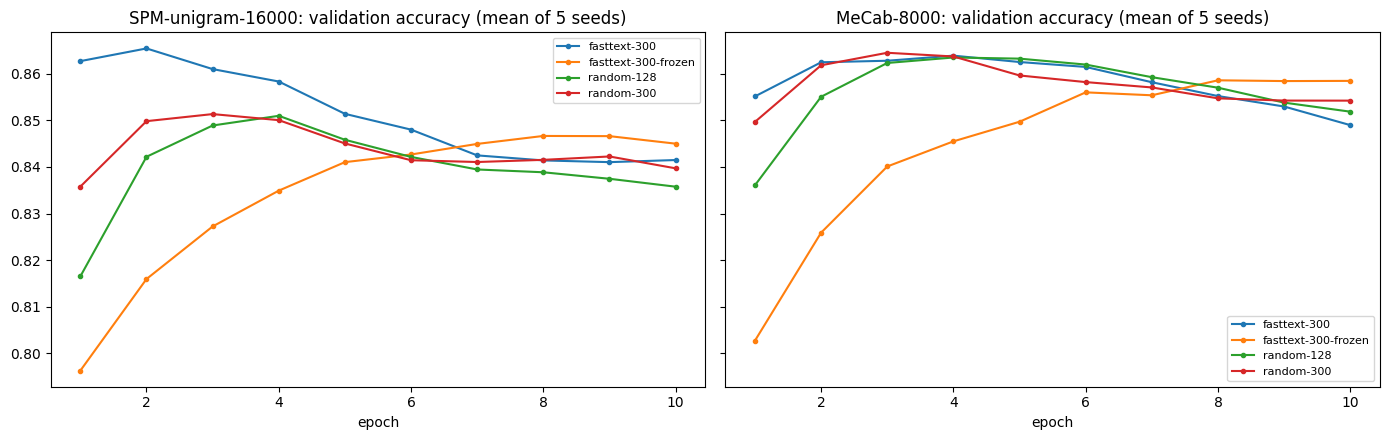

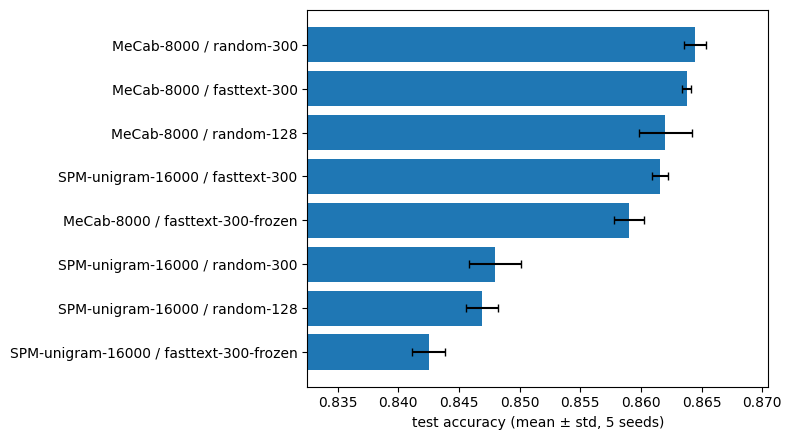

In [14]:
hist = pd.DataFrame([dict(h, tokenizer=r['tokenizer'], setting=r['setting'], seed=r['seed']) for r in RESULTS for h in r['hist']])
curve = hist.groupby(['tokenizer', 'setting', 'epoch'])[['train_loss', 'val_acc']].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, name in zip(axes, TOK):
    for setting, g in curve[curve.tokenizer == name].groupby('setting'):
        ax.plot(g['epoch'], g['val_acc'], marker='o', ms=3, label=setting)
    ax.set_title(f'{name}: validation accuracy (mean of 5 seeds)')
    ax.set_xlabel('epoch')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

order = summary['test_mean'].sort_values().index
plt.figure(figsize=(8, 4.5))
plt.barh([f'{a} / {b}' for a, b in order], summary.loc[order, 'test_mean'], xerr=summary.loc[order, 'test_std'], capsize=3)
plt.xlim(summary['test_mean'].min() - 0.01, summary['test_mean'].max() + 0.006)
plt.xlabel('test accuracy (mean ± std, 5 seeds)')
plt.tight_layout()
plt.show()

### 결과 해석

| 토크나이저 | 임베딩 | 검증 | 테스트 | 최고 에폭 |
|---|---|---|---|---|
| MeCab-8000 | random-128 (v2 설정) | 0.8647 ± 0.0017 | 0.8620 ± 0.0022 | 4.2 |
| MeCab-8000 | random-300 | 0.8649 ± 0.0022 | **0.8645 ± 0.0009** | 3.4 |
| MeCab-8000 | fasttext-300 | 0.8646 ± 0.0012 | 0.8638 ± 0.0004 | 3.4 |
| MeCab-8000 | fasttext-300-frozen | 0.8600 ± 0.0012 | 0.8590 ± 0.0012 | 8.6 |
| SPM-unigram-16000 | random-128 (v2 설정) | 0.8515 ± 0.0006 | 0.8469 ± 0.0013 | 3.8 |
| SPM-unigram-16000 | random-300 | 0.8519 ± 0.0029 | 0.8480 ± 0.0022 | 2.8 |
| SPM-unigram-16000 | **fasttext-300** | **0.8654 ± 0.0006** | 0.8616 ± 0.0007 | 2.0 |
| SPM-unigram-16000 | fasttext-300-frozen | 0.8479 ± 0.0021 | 0.8425 ± 0.0014 | 8.0 |

- **재현 확인**: `random-128`은 v2와 시드별 숫자까지 똑같이 나왔다. 같은 조건에서 비교한 결과라고 볼 수 있다.
- **SentencePiece는 fastText 덕을 크게 봤다.** 같은 300차원 무작위 대비 같은 시드끼리 테스트 **+1.36%p ± 0.27%p**였고, 시드 5개 모두 올랐다(1.06~1.76%p). 검증 0.8654로 8개 설정 중 가장 높았다. 1에폭부터 검증 0.863으로 출발해 2에폭에 최고가 됐다.
- **MeCab은 거의 변화가 없었다**(-0.07%p ± 0.07%p).
- **그래서 v2 결론이 달라진다.** 무작위 임베딩에서는 MeCab이 1.5%p 앞섰지만, fastText로 시작하면 SPM-unigram-16000(테스트 0.8616)이 v2의 MeCab-8000(0.8620)과 거의 같아진다. 검증으로 고르면 SPM+fastText(0.8654)와 MeCab random-300(0.8649)이 0.05%p 차이라 사실상 동률이다. 테스트로 보면 MeCab random-300이 0.29%p 높다.
- **벡터를 고정하면 손해다.** 두 토크나이저 모두 -0.5%p 정도 떨어졌다(SPM -0.55%p ± 0.24%p, MeCab -0.54%p ± 0.14%p). 검증 정확도가 8~9에폭까지 천천히 오르다 멈춘다. 이웃 단어를 보면 `노잼`과 가장 가까운 단어가 `꿀잼`이었다. fastText는 비슷한 문맥에 나오는 단어를 가깝게 두기 때문에, 반대 감정의 단어도 붙어 있다. 감정 분류에 맞게 벡터를 다시 학습(미세조정)해야 하는 이유로 보인다.
- **차원만 키운 효과는 작다.** `random-128` → `random-300`은 테스트 +0.11~0.25%p였다. SentencePiece의 +1.4%p는 차원이 아니라 사전학습 덕분이다.
- **fastText 사전 포함률은 둘 다 높았다**(SPM 91.7%, MeCab 93.9%). 그래서 포함률 차이로는 효과 차이를 설명할 수 없다.

**왜 SentencePiece만 덕을 봤나 (추측, 확인하지 않음):** fastText `cc.ko`는 공백으로 나뉜 웹 문서로 학습했다. 그래서 `▁영화가`처럼 어절에 가까운 SentencePiece 조각에는 쓸 만한 벡터가 있었을 것이다. 반면 MeCab의 `이`, `는`, `하` 같은 짧은 형태소는 웹 문서에서 단독 단어로 잘 나오지 않아 벡터가 덜 쓸모 있었을 수 있다. 확인하려면 SentencePiece 조각을 어절형(`▁`로 시작)과 조각형으로 나눠, 각각의 성능 기여를 따로 봐야 한다.

## 회고

### 진행하면서 막혔던 부분과 해결

| 막힌 부분 | 원인 | 해결 |
|---|---|---|
| 과제 원본 `sp_tokenize()`를 그대로 쓰면 `TypeError` | `EncodeAsIds`는 list를 돌려주는데 `pad_sequence`는 tensor만 받는다 | `torch.tensor(ids)`로 바꾸는 한 줄만 고치고, 원본 줄을 `# 📄 원본` / `# 🔧 수정`으로 나란히 남겼다 |
| v1에서 "MeCab이 1%p 높다", "vocab이 크면 떨어진다"를 결론으로 썼음 | 시드 1개로 한 번 돌리고, 테스트셋으로 바로 설정을 비교했다. 차이가 우연인지, 테스트로 골라서 부풀려졌는지 알 수 없었다 | 학습 데이터에서 검증 10%를 떼어 설정과 에폭은 검증으로만 골랐다. 테스트는 모델마다 한 번만 쟀고, 설정마다 시드 5개로 돌렸다 |
| v1 회고의 "희귀 토큰 때문"이 확인되지 않은 설명이었음 | 결과를 보고 그럴듯한 이유를 붙였을 뿐, 숫자로 확인하지 않았다 | 토크나이저마다 희귀 토큰 비율, `<unk>` 비율, 문장당 토큰 수, 잘리는 비율을 셌다. 그 결과 설명이 틀렸다는 것을 확인했다 |
| Okt 형태소 분석이 742초 걸림 | Okt는 MeCab(13초)보다 약 57배 느리다. vocab 크기마다 다시 분석하면 시간이 몇 배로 늘어난다 | 형태소 분석 결과를 한 번만 만들어 두고 vocab 크기별 사전 만들기에 재사용했다. Kkma는 더 느려서 본 실험에서는 빼고, 따로 노트북을 만들어 병렬로 돌렸다 |
| Kkma 병렬 분석이 예상(7분)보다 5배 오래 걸림 | 1,000개로 잰 속도로는 11프로세스에 7분이면 될 줄 알았는데, 중간에 10분 넘게 멈춘 구간이 두 번 있었다. 원인은 확인하지 못했다 | 끝까지 기다려 35.8분에 끝났다. 분석 결과를 파일로 저장해 두어 다시 돌릴 때는 건너뛰게 했다 |
| Colab 탭을 AI가 조작하다 멈춤 | 다른 세션이 같은 Chrome 확장을 쓰면서 연결된 프로필이 계속 바뀌었다 | 노트북 업로드와 실행은 직접 하고 실행된 노트북을 받아서 결과를 정리했다 |

### 실습을 통해 알게 된 것

SentencePiece가 더 높을 거라는 예상과 달리, 감정 분석 정확도는 MeCab이 SentencePiece보다 높았다. MeCab-8000이 검증 0.8647 ± 0.0017, SPM 최고인 unigram-16000이 검증 0.8515 ± 0.0006이었다. 같은 시드끼리 테스트 정확도를 비교하면 1.51%p ± 0.22%p 차이였고 시드 5개 모두 MeCab이 높았다. v1에서 본 1%p 차이는 우연이 아니라 실제 차이였다.

반면 SentencePiece의 `model_type`과 `vocab_size`는 거의 영향이 없었다. 6개 설정의 검증 평균이 0.8489~0.8515로 0.26%p 안에 있었다. 시드를 바꿨을 때 흔들리는 정도(표준편차 0.06~0.23%p)와 비슷한 폭이다. v1에서는 테스트 정확도 순서(4000 > 8000 > 16000)를 보고 "vocab이 크면 떨어진다"고 썼다. 하지만 검증으로 보면 오히려 16000이 SPM 중 가장 높았다. 시드 하나, 테스트셋 하나로는 0.1%p 단위의 순서를 믿으면 안 된다는 것을 알게 됐다.

차이가 어디서 오는지도 숫자로 확인했다. MeCab-4000은 검증 토큰의 7.8%가 사전에 없는 `<unk>`였는데도(SPM은 약 0.1%) SPM보다 1%p 넘게 높았다. 그러니 차이는 모르는 단어를 얼마나 덮느냐가 아니라 문장을 어떤 단위로 나누느냐에서 온다. 오답을 보니 SPM은 `▁좋구 / 만`, `▁보고나면`, `지않는다`처럼 어간과 어미를 한 조각으로 붙이는 경우가 많았다. `공원`을 `▁공 / 원`, `소식`을 `▁소 / 식`으로 쪼개기도 했다. MeCab은 `좋 / 구만`, `보 / 고 / 나 / 면`처럼 감정을 담은 어간을 따로 떼어 낸다. 그래서 어미가 달라도 같은 어간이 같은 토큰으로 모이기 쉽다.

나중에 Kkma까지 비교해 보니 이 해석에 근거가 하나 더 생겼다. 어간과 어미를 떼어 내는 MeCab(검증 0.8647)과 Kkma(0.8639)는 거의 같았다. 반면 `복잡하고`, `버텼다`처럼 붙여 두는 Okt(0.8532)는 SentencePiece(0.8515)와 비슷하게 낮았다. 그런데 SPM-unigram-4000은 문장당 20.2토큰으로 Kkma(20.3)만큼 잘게 나누는데도 0.8514에 그쳤다. 잘게 나누는 것 자체보다 형태소 경계에서 나누는지가 중요해 보인다. 다만 모델 하나로 본 결과라 단정하지는 않는다.

교수님이 말씀하신 "loss만 보고 판단한 실험은 실패"도 다시 확인했다. 러닝 커브를 그려 보니 학습 loss는 10에폭까지 계속 줄었지만 검증 정확도는 4에폭 전후에서 가장 높고 그 뒤로 계속 떨어졌다. v1의 4에폭은 운 좋게 맞은 값이었다. 10에폭을 그대로 썼다면 1~1.5%p 손해를 봤을 것이다.

선택 과제로 fastText 사전학습 벡터를 붙여 보니 결론이 한 번 더 바뀌었다. 임베딩을 fastText로 시작하면 SentencePiece가 같은 시드끼리 1.36%p ± 0.27%p 올라, 테스트 0.8616으로 v2의 MeCab(0.8620)과 거의 같아졌다. MeCab은 -0.07%p로 거의 그대로였다. 무작위 임베딩에서 본 1.5%p 차이는 토크나이저만의 차이가 아니라 임베딩을 어떻게 시작하느냐와 얽혀 있었다. 토크나이저를 비교할 때는 임베딩 조건까지 같이 적어야 한다는 것을 알게 됐다.

### 개인 실험 요약

원본 과제 흐름(Step 0~4)은 그대로 두고 원본에 없는 셀은 모두 `[개인 실험]`으로 표시했습니다.

1. **데이터 분할**: v1은 테스트셋으로 바로 비교했습니다. 이번에는 학습 데이터에서 라벨 비율을 유지한 채 검증 10%를 떼어 냈습니다(학습 131,564 / 검증 14,618 / 테스트 49,157). 설정과 에폭은 검증으로만 고르고 테스트는 모델마다 한 번만 쟀습니다.
2. **시드 5개**: 1%p 차이가 우연인지 궁금해서 토크나이저 10개를 시드 5개씩, 모두 50번 학습했습니다. MeCab과 SPM 최고 설정의 차이는 1.51%p ± 0.22%p였습니다. 시드별로는 1.13~1.69%p로 5번 모두 MeCab이 높았습니다.
3. **같은 vocab 크기 비교**: v1은 MeCab만 vocab 16000이라 조건이 달랐습니다. 그래서 MeCab도 4000/8000/16000으로 맞췄더니 모든 크기에서 MeCab이 1.1~1.6%p 높았습니다(테스트 평균 기준).
4. **토큰 통계**: v1 회고의 "희귀 토큰" 설명이 맞는지 보려고 vocab 중 학습 데이터에 5번 미만 나온 토큰 비율을 셌습니다. SPM은 0.05~0.85%로 거의 없어서 설명이 틀렸다는 걸 확인했습니다. `<unk>` 비율은 SPM 약 0.1%, MeCab 2.6~7.8%, Okt 8.1%였습니다.
5. **러닝 커브**: 4에폭이 적당했는지 보려고 10에폭 동안 에폭마다 학습 loss와 검증 정확도를 기록했습니다. 최고 검증 에폭은 3~6(평균 3.4~5.0)이었고 그 뒤로는 loss가 줄어도 정확도가 떨어졌습니다. SPM-bpe-8000은 시드 하나가 3에폭에서 크게 흔들려 평균 곡선이 0.787까지 내려갔다가 돌아왔습니다.
6. **before/after (MAX_LEN 60 → 128)**: vocab 4000은 문장이 잘게 쪼개져 5.1%가 60토큰에서 잘렸습니다. 이게 손해였는지 다른 조건은 그대로 두고 확인했습니다. SPM-unigram-4000은 검증 +0.14%p, MeCab-8000은 +0.04%p로 시드 표준편차 수준이었습니다. 잘림은 차이의 원인이 아니었습니다.
7. **Okt 추가**: 과제가 "Mecab, kkma, Okt 등과 비교"라서 Okt도 넣었습니다. 검증 0.8532 ± 0.0012로 MeCab과 SPM 사이였습니다. 형태소 분석이 742초로 MeCab의 약 57배 걸렸습니다.
8. **오답 분석**: 시드 0 기준으로 둘 다 맞힌 리뷰가 79.1%, MeCab만 맞힌 리뷰가 7.1%, SPM만 맞힌 리뷰가 5.4%였습니다. 리뷰 길이를 4구간으로 나눠도 모든 구간에서 MeCab이 1.2~1.9%p 높아 길이에 따라 갈리는 차이는 아니었습니다. SPM만 맞힌 리뷰에는 띄어쓰기가 없는 문장이 있었습니다. MeCab이 `홍상수형님`을 `홍상 / 수형`으로 잘못 나눈 경우가 그 예입니다.
9. **[선택 과제] fastText 사전학습 벡터**: 과제 안내의 선택 항목이라, 임베딩을 fastText 한국어 벡터(`cc.ko.300`)로 시작해 봤습니다. 차원이 커진 효과와 구분하려고 300차원 무작위 임베딩도 같이 돌렸습니다(토크나이저 2개 × 설정 4개 × 시드 5개). 먼저 v2 설정을 다시 돌려 시드별 숫자까지 똑같이 나오는 것을 확인했습니다. SentencePiece는 미세조정하면 300차원 무작위보다 +1.36%p ± 0.27%p 올랐고, 시드 5개 모두 올랐습니다. MeCab은 -0.07%p ± 0.07%p로 거의 그대로였습니다. 벡터를 고정하면 둘 다 약 0.5%p 떨어졌습니다. 이웃 단어를 보니 `노잼`과 가장 가까운 단어가 `꿀잼`이어서, 감정 분류에 맞게 벡터를 다시 학습해야 한다는 걸 알 수 있었습니다.
10. **[추가 실험] Kkma**: 과제 안내의 "Mecab, kkma, Okt 등"에서 빠진 Kkma가 실제로 얼마나 느리고 성능은 어떤지 궁금해서 따로 돌렸습니다. 1,000개로 재니 1개당 23.7ms라 한 프로세스로는 약 77분(MeCab의 약 356배) 걸릴 속도였습니다. 그래서 CPU 11개 프로세스로 병렬 분석했는데, 그래도 35.8분이 걸렸습니다. 정확도는 Kkma-16000이 검증 0.8639 ± 0.0019로 MeCab-8000(0.8647)과 거의 같았고, Okt·SentencePiece보다 1%p 넘게 높았습니다.

### 어려웠던 것

가장 어려웠던 건 형태소와 서브워드의 차이였다. 둘 다 문장을 작은 조각으로 나누는 건 같다. 형태소 분석기는 사람이 만든 사전과 문법으로 `좋 / 구만`처럼 뜻이 있는 단위로 나눈다. SentencePiece는 학습 데이터에서 자주 같이 나오는 글자를 묶어서 `▁좋구 / 만`처럼 나눈다. 말로는 알겠는데 이 차이가 왜 정확도 1.5%p 차이로 이어지는지는 아직 끝까지 설명하지 못하겠다.

실험 설계도 어려웠다. 검증을 따로 떼고 시드를 여러 번 돌리고 vocab 크기를 맞추는 것처럼, 공정하게 비교하려면 무엇을 같게 둬야 하는지 정하는 게 코드보다 어려웠다.

결과 해석도 마찬가지였다. v1 결과를 처음 봤을 때는 표의 순서를 그대로 결론으로 읽었다. 0.8344와 0.8332의 차이에 이유를 붙이고 그럴듯한 설명(희귀 토큰)까지 썼다. 시드를 바꿔 다시 돌려 보니 그 정도 차이는 시드만 바꿔도 생기는 크기였다. 숫자를 보고 바로 해석하기 전에, 그 차이가 흔들림보다 큰지부터 확인해야겠다고 느꼈다.

### 좋았던 점과 아쉬웠던 점

코랩 Pro A100으로 50번의 실험이 16분 만에 끝나서 좋았다. 덕분에 시드 5개 반복이나 before/after 같은 실험을 부담 없이 더할 수 있었다.

아쉬운 점은 개념을 끝까지 이해하지 못한 것과 AI에 많이 기댄 것이다. 실험 설계와 코드 대부분을 AI와 함께 만들었고 나는 결과를 보고 판단하는 쪽에 가까웠다. 결과는 나왔지만 형태소와 서브워드의 원리는 아직 애매하다.

### 처음 기대와 실제

처음에는 SentencePiece가 MeCab보다 감정 분석 정확도가 높을 거라고 생각했다. 영화 리뷰에는 신조어, 오타, 띄어쓰기가 틀린 문장이 많다. SentencePiece는 형태소 분석기나 사전에 의존하지 않고 데이터만으로 단어 조각을 만들기 때문에 이런 리뷰에 더 잘 맞을 거라고 봤다. 실제로는 MeCab이 시드 5개 모두에서 1.5%p 정도 높았다. 모르는 단어가 7.8%나 되는 MeCab-4000도 SentencePiece보다 높았다. 그런데 선택 과제에서 fastText 벡터로 시작하니 SentencePiece가 MeCab 수준까지 올라왔다. 처음 예상이 완전히 틀린 건 아니었고, 조건에 따라 답이 달라졌다.

가장 기억에 남는 건 러닝 커브였다. 학습 loss는 10에폭까지 계속 줄었는데 검증 정확도는 4에폭 전후부터 오히려 떨어졌다. 6주차 AutoEncoder에서 "loss만 보면 착각한다"는 걸 배웠다. 모델도 데이터도 다른 이번 실험에서 같은 현상이 나타나서 확실히 와닿았다.

### 현장에 쓴다면

MeCab과 SentencePiece를 섞어서 쓸 것 같다. MeCab으로 먼저 어간과 어미를 나누면 이번에 본 장점(어미가 달라도 같은 어간이 같은 토큰으로 모임)을 살릴 수 있다. 그 위에 SentencePiece를 적용하면 사전에 없는 신조어도 `<unk>` 대신 조각으로 남길 수 있다. 다만 이번에는 이 조합을 직접 실험하지 못해서 정말 더 나은지는 확인이 필요하다. 하나만 고른다면 이번 결과로는 MeCab이다. 무작위 임베딩에서는 성능이 1.5%p 높고, 20만 문장을 13초에 처리할 만큼 빠르다. 다만 fastText 같은 사전학습 벡터를 쓸 수 있으면 SentencePiece도 MeCab과 거의 같은 성능이 나왔다. 그 경우에는 설치와 사전 관리가 필요 없는 SentencePiece도 충분히 고를 만하다. Kkma는 정확도가 MeCab과 같았지만, 병렬로 돌려도 MeCab보다 약 165배 오래 걸려서(35.8분 vs 13초) 고르지 않을 것이다.

### 앞으로 해 볼 것

- 현장에 쓴다면 고를 방식인 "MeCab으로 먼저 나누고 SentencePiece 적용"을 같은 조건(검증 분리, 시드 5개)으로 비교해 보고 싶다.
- 형태소와 서브워드의 차이를 내 말로 설명할 수 있게, 리뷰 몇 개를 손으로 직접 나눠 보고 두 토크나이저 결과와 비교해 볼 것이다.
- 다음 실험은 설계와 코드를 먼저 직접 짜 보고 막힐 때만 AI에게 물어볼 생각이다.
- fastText가 왜 SentencePiece에만 효과가 컸는지 확인해 보고 싶다. SentencePiece 조각을 어절형(`▁`로 시작)과 조각형으로 나눠, 어느 쪽에서 효과가 나오는지 따로 볼 생각이다.
- Transformer처럼 다른 모델에서도 토크나이저 순서가 같은지 보고 싶다.

### 동료 피드백

받은 피드백은 없다.